# [58기-데타출동] 데이터 시각화 프로젝트

## Steam 게임 특성별 게임 가격과 플레이타임 간의 관계 (가제)
### <1주차> 데이터 점검 및 전처리

### #00 프로젝트 개요

> 2025년 3월 Steam 게임의 특성(장르, DLC 유무, 도전과제 수)에 따라 가격대별 플레이타임에 어떠한 차이가 나타나는지 비교·분석한다.   

**핵심 질문**:   
- Q1. 어느 가격대의 게임에서 플레이타임이 가장 길게 나타나는가?   
- Q2. 게임의 특성(장르, DLC 유무, 도전과제 수)에 따라 가격대별 플레이타임 차이가 나타나는가?   

**비교 축**:   

- 가격대(`가격대`, 파생)   
- DLC 유무(`DLC`, 파생)   
- 10개의 장르(`장르`, 파생)   
- 도전과제 수(`도전과제`, 파생)   

### #01 데이터셋 비교 및 선정

#### 1. 원본 데이터 구성

> 원본 데이터는 수집 시점(2024년 5월, 2025년 3월)과 전처리 여부(Cleaned, Full)에 따라 총 4개의 파일로 구성되어 있다.


|수집 시점|Full|Cleaned|
|---|---|---|
|2024년 5월|games_may2024_full.csv|games_may2024_cleaned.csv|
|2025년 3월|games_march2025_full.csv|games_march2025_cleaned.csv|

#### 2. 수집 시점에 따른 데이터 선정

> 데이터의 최신성 및 분석 목적과의 적합성을 선정 기준으로 하여,   
> 다음과 같은 이유로 2024년 5월 데이터를 제외하고 2025년 3월 데이터를 우선 선정하였다.
 - 본 프로젝트는 연도별 변화 추이가 아닌 게임의 기본 특성과 플레이타임 간의 관계를 분석하는 것이 목적이므로 서로 다른 시점의 데이터를 모두 활용할 필요성이 낮다.
 - 동일한 게임이 두 데이터셋에 중복 포함될 가능성을 고려하여 단일 시점의 데이터를 활용하고자 한다.
 - 분석 시점의 최신성을 고려하여 상대적으로 최근에 수집된 ***2025년 3월 데이터***를 우선 선정하였다.

#### 3. 최종 데이터셋 선정

> 원본 제공자의 설명에 따르면 Cleaned 버전은 Full 버전에서 AppID가 10의 배수인 게임을 추출하고, 게임 이름에 `playtest`, `dedicated server`, `test server`가 포함된 항목을 제거한 데이터이다. 제공자의 설명상 중복 게임 항목과 테스트·서버용 버전은 포함되지 않는다.

1. 준비 작업

In [3]:
# 라이브러리 참조
import pandas as pd
import numpy as np
import ast
from helpers import *

In [4]:
# 데이터 불러오기
steam_full = pd.read_csv("games_march2025_full.csv", encoding="utf-8")
steam_cleaned = pd.read_csv("games_march2025_cleaned.csv", encoding="utf-8")

2. 두 데이터셋의 기본 구조 비교

In [5]:
# 데이터의 차원과 크기 확인
print("full 데이터 차원:", steam_full.ndim)
print("full 데이터 크기:", steam_full.shape)
print("cleaned 데이터 차원:", steam_cleaned.ndim)
print("cleaned 데이터 크기:", steam_cleaned.shape)

full 데이터 차원: 2
full 데이터 크기: (94948, 47)
cleaned 데이터 차원: 2
cleaned 데이터 크기: (89618, 47)


3. 변수 구성 확인

In [6]:
# 변수명과 자료형 비교
print("변수명 동일:", steam_full.columns.equals(steam_cleaned.columns))
print("자료형 동일:", steam_full.dtypes.equals(steam_cleaned.dtypes))

변수명 동일: True
자료형 동일: True


In [7]:
# 식별자 기준 제외 내역: 실제 제외 게임 확인
print('Full appid 중복 행 수:', steam_full['appid'].duplicated().sum())
print('Cleaned appid 중복 행 수:', steam_cleaned['appid'].duplicated().sum())
removed_games = steam_full.loc[~steam_full['appid'].isin(steam_cleaned['appid'])]
print('Cleaned에 없는 appid에 해당하는 Full 행 수:', len(removed_games))
display(removed_games[['appid', 'name']].head(20))

Full appid 중복 행 수: 0
Cleaned appid 중복 행 수: 0
Cleaned에 없는 appid에 해당하는 Full 행 수: 5330


,appid,name
4,488824,Tom Clancy's Rainbow Six® Siege
5,488822,Tom Clancy's Rainbow Six® Siege
6,488821,Tom Clancy's Rainbow Six® Siege
7,488823,Tom Clancy's Rainbow Six® Siege
19,1952710,BACKGAMMON Playtest
22,2912110,Baldur's Gate 3 Playtest
57,1584640,NARAKA: BLADEPOINT Playtest
69,2936120,Marvel Rivals Playtest
93,1489280,鬼谷八荒 Playtest
119,52003,Portal


| 비교 항목 | Full | Cleaned |
|---|---:|---:|
| 차원 수 (ndim) | 2 | 2 |
| 행 수 | 94,948 | 89,618 |
| 열 수 | 47 | 47 |
| 제거된 행 수 | - | 5,330 |
| 데이터 유지율 | 100% | 94.39% |
| 데이터 제거율 | 0% | 5.61% |

- 두 데이터셋의 변수 수는 47개로 동일하고, 변수명과 자료형이 모두 동일하다.
- Cleaned 버전은 Full 버전보다 5,330개 행(전체 데이터의 약 5.61%)이 적다.

> 본 분석에서는 제공자의 정제 설명과 구조 비교를 바탕으로 중복 게임 항목과 테스트·서버용 버전은 포함하지 않은 ***Cleaned 버전***을 최종 분석 데이터셋으로 선정한다.

### #02 데이터 품질 점검

#### 1. Cleaned 데이터 구조 확인

In [8]:
# 데이터의 차원과 크기
print("cleaned 데이터 차원:", steam_cleaned.ndim)
print("cleaned 데이터 크기:", steam_cleaned.shape)

cleaned 데이터 차원: 2
cleaned 데이터 크기: (89618, 47)


In [9]:
# 각 변수의 정보 확인
steam_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     89618 non-null  int64  
 1   name                      89618 non-null  str    
 2   release_date              89618 non-null  str    
 3   required_age              89618 non-null  int64  
 4   price                     89618 non-null  float64
 5   dlc_count                 89618 non-null  int64  
 6   detailed_description      89421 non-null  str    
 7   about_the_game            89398 non-null  str    
 8   short_description         89498 non-null  str    
 9   reviews                   10401 non-null  str    
 10  header_image              89618 non-null  str    
 11  website                   41114 non-null  str    
 12  support_url               44110 non-null  str    
 13  support_email             78798 non-null  str    
 14  windows          

In [10]:
# 결측치 여부 확인
my_qtcheck.check_missing_values(steam_cleaned)

,Missing Count,Missing Ratio (%)
appid,0,0.000000
name,0,0.000000
release_date,0,0.000000
required_age,0,0.000000
price,0,0.000000
dlc_count,0,0.000000
detailed_description,197,0.219822
about_the_game,220,0.245486
short_description,120,0.133902
reviews,79217,88.394073


In [11]:
# 행 단위 완전 중복 확인, 현 단계에서는 제거하지 않음
my_qtcheck.check_duplicates(steam_cleaned, drop=False)

중복된 행의 수: 0


,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,...,771,7101,74,0,117698,"{'Open World': 32644, 'Action': 23539, 'Multip...",87,1803832,92,17517
4,359550,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,3.99,9,Edition Comparison Ultimate Edition The Tom Cl...,“One of the best first-person shooters ever ma...,"Tom Clancy's Rainbow Six® Siege is an elite, t...",NaN,...,682,2434,306,80,89916,"{'FPS': 9831, 'PvP': 9162, 'e-sports': 9072, '...",84,1168020,76,12608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89613,2115110,Outrun Them,2024-02-29,0,3.99,0,The name of the game is literally the game. Ou...,The name of the game is literally the game. Ou...,It's all in the name.. outrun them.,NaN,...,0,0,0,0,0,"{'2D Platformer': 91, 'Runner': 85, 'Platforme...",-1,-1,-1,-1
89614,1174200,Lands of Pharaoh: Episode 1,2020-01-07,0,10.00,0,Join Our Discord Channel About the Game Briefl...,Briefly: Lands of Pharaoh is a third person vi...,Lands of Pharaoh is a multi-camera-angle based...,NaN,...,0,0,0,0,0,"{'Action': 43, 'Adventure': 41, 'Indie': 41, '...",-1,-1,-1,-1
89615,1160190,Player One,2019-10-10,0,1.99,0,Player One is a new 3D game where you take con...,Player One is a new 3D game where you take con...,"3D Game, Thirdperson Platformer",NaN,...,0,0,0,0,0,"{'Indie': 31, 'Early Access': 21}",-1,-1,-1,-1
89616,3380340,DragonRoad,2025-01-25,0,29.99,0,"This is an open world game on 3D, also a m...","This is an open world game on 3D, also a m...","This is an open world game on 3D, Also a missi...",NaN,...,0,0,0,0,0,"{'RPG': 117, 'Action-Adventure': 111, 'Strateg...",-1,-1,-1,-1


#### 2. 분석 변수 선정 및 추출

> 게임의 주요 특성이 플레이타임과 어떠한 관계를 가지는지 파악하기 위해 아래 변수들을 주요 분석 변수로 선정하였다.

| 원본 변수 | 현재 의미·역할 | 계획한 파생 변수 |
|---|---|---|
| `appid`, `name` | 식별 및 특이값 확인용 | 없음 |
| `price` | 게임의 가격 | 가격대 |
| `genres` | 리스트 형태를 담은 문자열, 다중 레이블 | 장르별 포함 여부 |
| `dlc_count` | DLC 개수 | DLC 유무 |
| `achievements` | 도전과제 개수 | 도전과제 구간 |
| `median_playtime_forever` | 게임별 누적 플레이타임 중앙값, 분 | 최종 종속변수 후보 |
| `average_playtime_forever` | 게임별 누적 플레이타임 평균, 분 | 비교용 후보 |

> 불필요한 변수로 인한 분석의 복잡성을 줄이고자 해당 변수들을 우선 추출한다.

In [12]:
# 필요한 변수만 필터링
df1 = steam_cleaned.filter(['appid', 'name', 'price', 'genres', 'dlc_count', 'achievements', 'median_playtime_forever', 'average_playtime_forever'])
df1.head()

,appid,name,price,genres,dlc_count,achievements,median_playtime_forever,average_playtime_forever
0,730,Counter-Strike 2,0.00,"['Action', 'Free To Play']",1,1,5174,33189
1,578080,PUBG: BATTLEGROUNDS,0.00,"['Action', 'Adventure', 'Massively Multiplayer...",0,37,0,0
2,570,Dota 2,0.00,"['Action', 'Strategy', 'Free To Play']",2,0,898,43031
3,271590,Grand Theft Auto V Legacy,0.00,"['Action', 'Adventure']",0,77,7101,19323
4,359550,Tom Clancy's Rainbow Six® Siege,3.99,['Action'],9,0,2434,14204


#### 3. 선택 변수의 데이터 품질 점검

In [13]:
# 데이터의 차원과 크기
print("cleaned 데이터 차원:", df1.ndim)
print("cleaned 데이터 크기:", df1.shape)

cleaned 데이터 차원: 2
cleaned 데이터 크기: (89618, 8)


In [14]:
# 각 변수의 정보 확인
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     89618 non-null  int64  
 1   name                      89618 non-null  str    
 2   price                     89618 non-null  float64
 3   genres                    89618 non-null  str    
 4   dlc_count                 89618 non-null  int64  
 5   achievements              89618 non-null  int64  
 6   median_playtime_forever   89618 non-null  int64  
 7   average_playtime_forever  89618 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 9.8 MB


In [15]:
# 결측치 여부 확인
my_qtcheck.check_missing_values(df1)

,Missing Count,Missing Ratio (%)
appid,0,0.0
name,0,0.0
price,0,0.0
genres,0,0.0
dlc_count,0,0.0
achievements,0,0.0
median_playtime_forever,0,0.0
average_playtime_forever,0,0.0


In [16]:
# 행 단위 완전 중복 확인, 현 단계에서는 제거하지 않음
my_qtcheck.check_duplicates(df1, drop=False)

중복된 행의 수: 0


,appid,name,price,genres,dlc_count,achievements,median_playtime_forever,average_playtime_forever
0,730,Counter-Strike 2,0.00,"['Action', 'Free To Play']",1,1,5174,33189
1,578080,PUBG: BATTLEGROUNDS,0.00,"['Action', 'Adventure', 'Massively Multiplayer...",0,37,0,0
2,570,Dota 2,0.00,"['Action', 'Strategy', 'Free To Play']",2,0,898,43031
3,271590,Grand Theft Auto V Legacy,0.00,"['Action', 'Adventure']",0,77,7101,19323
4,359550,Tom Clancy's Rainbow Six® Siege,3.99,['Action'],9,0,2434,14204
...,...,...,...,...,...,...,...,...
89613,2115110,Outrun Them,3.99,"['Indie', 'Early Access']",0,6,0,0
89614,1174200,Lands of Pharaoh: Episode 1,10.00,"['Action', 'Adventure', 'Indie', 'Strategy']",0,0,0,0
89615,1160190,Player One,1.99,"['Indie', 'Early Access']",0,0,0,0
89616,3380340,DragonRoad,29.99,"['Adventure', 'RPG', 'Simulation', 'Strategy']",0,34,0,0


In [17]:
# 수치 변수의 기술통계량 확인
numeric_columns = ['price', 'dlc_count', 'achievements',
                   'median_playtime_forever', 'average_playtime_forever']
my_qtcheck.numerical_summary(df1, numeric_columns)

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,...,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
price,89618.0,7.309623,13.331073,0.0,0.99,4.99,9.99,999.98,0.464854,diff,...,0.046263,0,0.0,4146,0.046263,20.716281,right tail,1129.900838,leptokurtic,log1p
dlc_count,89618.0,0.595583,15.351920,0.0,0.00,0.00,0.00,3427.00,inf,large_diff,...,0.158785,0,0.0,14230,0.158785,160.746945,right tail,31658.576535,leptokurtic,log1p
achievements,89618.0,20.552333,163.562418,0.0,0.00,5.00,20.00,9821.00,3.110467,large_diff,...,0.062889,0,0.0,5636,0.062889,28.460121,right tail,900.102293,leptokurtic,log1p
median_playtime_forever,89618.0,114.755853,8806.711196,0.0,0.00,0.00,0.00,1462997.00,inf,large_diff,...,0.089379,0,0.0,8010,0.089379,143.662254,right tail,21544.436634,leptokurtic,log1p
average_playtime_forever,89618.0,114.911882,6814.747948,0.0,0.00,0.00,0.00,1462997.00,inf,large_diff,...,0.089379,0,0.0,8010,0.089379,165.637725,right tail,30663.391455,leptokurtic,log1p


> 위에서 선택한 수치형 변수들은 변수 특성상 음수가 될 수 없으므로, 0 미만의 값을 비정상 값으로 판단한다.
> - price
> - dlc_count
> - achievements
> - median_playtime_forever
> - average_playtime_forever

> 최솟값은 모두 0이지만, `가격 999.98`, `DLC 3,427개`, `도전과제 9,821개`, `플레이타임 중앙값 1,462,997분` 등은 원자료 확인 대상이다.   

#### 4. 각 변수의 구조 점검

In [18]:
display(df1[numeric_columns].lt(0).sum().to_frame('음수 개수'))
for column in numeric_columns:
    print('상위값 확인:', column)
    display(df1.nlargest(5, column)[['appid', 'name', column]])

def inspect_genres(value):
    if pd.isna(value):
        return None, '결측'
    if isinstance(value, str) and not value.strip():
        return None, '빈 문자열'
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError, TypeError):
        return None, '해석 실패'
    if not isinstance(parsed, list):
        return None, '리스트 아님'
    if not parsed:
        return [], '빈 목록'
    if not all(isinstance(item, str) and item.strip() for item in parsed):
        return None, '목록 원소 확인 필요'
    return parsed, '정상 목록'

genre_check = df1['genres'].map(inspect_genres)
display(genre_check.map(lambda result: result[1]).value_counts().to_frame('게임 수'))
genre_lists = genre_check.map(lambda result: result[0])
genre_counts = genre_lists.explode().dropna().value_counts()
display(genre_counts.to_frame('장르별 포함 게임 수'))
# 한 게임이 여러 장르에 포함될 수 있어 합계는 전체 게임 수를 넘을 수 있다.


,음수 개수
price,0
dlc_count,0
achievements,0
median_playtime_forever,0
average_playtime_forever,0


상위값 확인: price


,appid,name,price
60133,2504210,The Leverage Game Business Edition,999.98
81168,2499620,The Leverage Game,999.98
64631,1200520,Ascent Free-Roaming VR Experience,999.00
84664,3013840,True Love,500.00
72266,253670,Aartform Curvy 3D 3.0,299.90


상위값 확인: dlc_count


,appid,name,dlc_count
7528,1196310,Fantasy Grounds VTT,3427
6270,252690,Fantasy Grounds Classic,2004
1090,221680,Rocksmith® 2014 Edition REMASTERED LEARN & PLAY,1191
55733,363890,RPG Maker MV,954
58421,1096900,RPG Maker MZ,767


상위값 확인: achievements


... (3 outputs left out)

상위값 확인: average_playtime_forever


,appid,name,average_playtime_forever
15124,938270,LoveKami -Healing Harem-,1462997
8280,707300,Hatsune Miku VR,991837
6811,745960,A Sky Full of Stars 仰望夜空的星辰,727941
8582,332790,Darkness Assault,533442
11851,626510,LoveKami -Useless Goddess-,364772


,게임 수
genres,
정상 목록,89406
빈 목록,212


,장르별 포함 게임 수
genres,
Indie,63189
Casual,38699
Action,36842
Adventure,35452
Simulation,18570
Strategy,17366
RPG,16342
Early Access,9113
Free To Play,8867


> 상위값 점검에서 확인한 극단값은 **유지**한다. 
> - `price`는 분석 대상(플레이타임 중앙값이 양수인 게임) 안에서 유료 게임 최댓값이 `99.99달러`이므로 `999.98달러`인 게임은 이미 범위 밖이다.   
> - `dlc_count`와 `achievements`는 유무·구간으로만 쓰므로 `3,427개`·`9,821개`가 구간 분류를 바꾸지 않는다.    
> - `median_playtime_forever` 상위 5개 게임(`LoveKami -Healing Harem-` `1,462,997분` 등)은 오류로 판단할 근거가 없어 제외하지 않되, 2주차 기술통계에서는 **중앙값·IQR을 기본**으로 보고하고 평균은 참고로만 적는다.   
> - 이 게임들이 속한 가격대·장르별로 게임 수와 최댓값을 함께 표시하여 일부 극단값이 평균에 미치는 영향을 확인한다.

#### 5. 0값 점검 및 종속변수 검토

> 0값은 변수의 특성에 따라 서로 다른 의미를 가지므로 일괄적으로 제거하지 않고, 변수별 0값의 개수와 비율을 분석하여 처리 기준을 검토하고자 한다.

In [19]:
# 수치형 변수의 0값 개수 및 비율 확인
numeric_df = df1[numeric_columns]

zero = numeric_df.eq(0).sum()
zero_ratio = zero / numeric_df.count() * 100

numeric_df_zero = zero.to_frame(name="0값 개수")
numeric_df_zero['0값 비율 (%)'] = zero_ratio.round(2)

numeric_df_zero

,0값 개수,0값 비율 (%)
price,14160,15.80
dlc_count,75388,84.12
achievements,41090,45.85
median_playtime_forever,81608,91.06
average_playtime_forever,81608,91.06


- 수치형 변수 중 분석의 종속변수로 사용하고자 하는 `median_playtime_forever`와 `average_playtime_forever`에서 0값이 모두 91.06%로 매우 높게 나타났다.

> 본 분석은 게임의 주요 특성과 플레이타임 간의 관계를 파악하는 것을 목적으로 하므로, **두 플레이타임이 모두 양수인 게임**을 임시 비교 대상으로 사용한다.

In [20]:
# 두 변수 모두 0보다 큰 값인 행만 필터링
playtime = df1.loc[(df1['median_playtime_forever'] > 0) & (df1['average_playtime_forever'] > 0)][['median_playtime_forever', 'average_playtime_forever']]
print('전체 게임 수:', len(df1))
print('두 지표 모두 양수인 게임 수:', len(playtime))

전체 게임 수: 89618
두 지표 모두 양수인 게임 수: 8010


- 전체 89,618개 중 두 지표가 모두 양수인 게임이 8,010개(8.94%)이다.
- 두 지표의 0값 개수는 각각 81,608개(91.06%)이다.

> 이를 통해 두 변수의 0값이 모두 동일한 행에서 발생한다는 것을 확인할 수 있다.

In [21]:
# 기술통계량 확인
playtime.describe().round(2)

,median_playtime_forever,average_playtime_forever
count,8010.00,8010.00
mean,1283.92,1285.66
std,29433.63,22762.81
min,1.00,1.00
25%,60.00,64.00
50%,213.00,218.00
75%,442.00,511.00
max,1462997.00,1462997.00


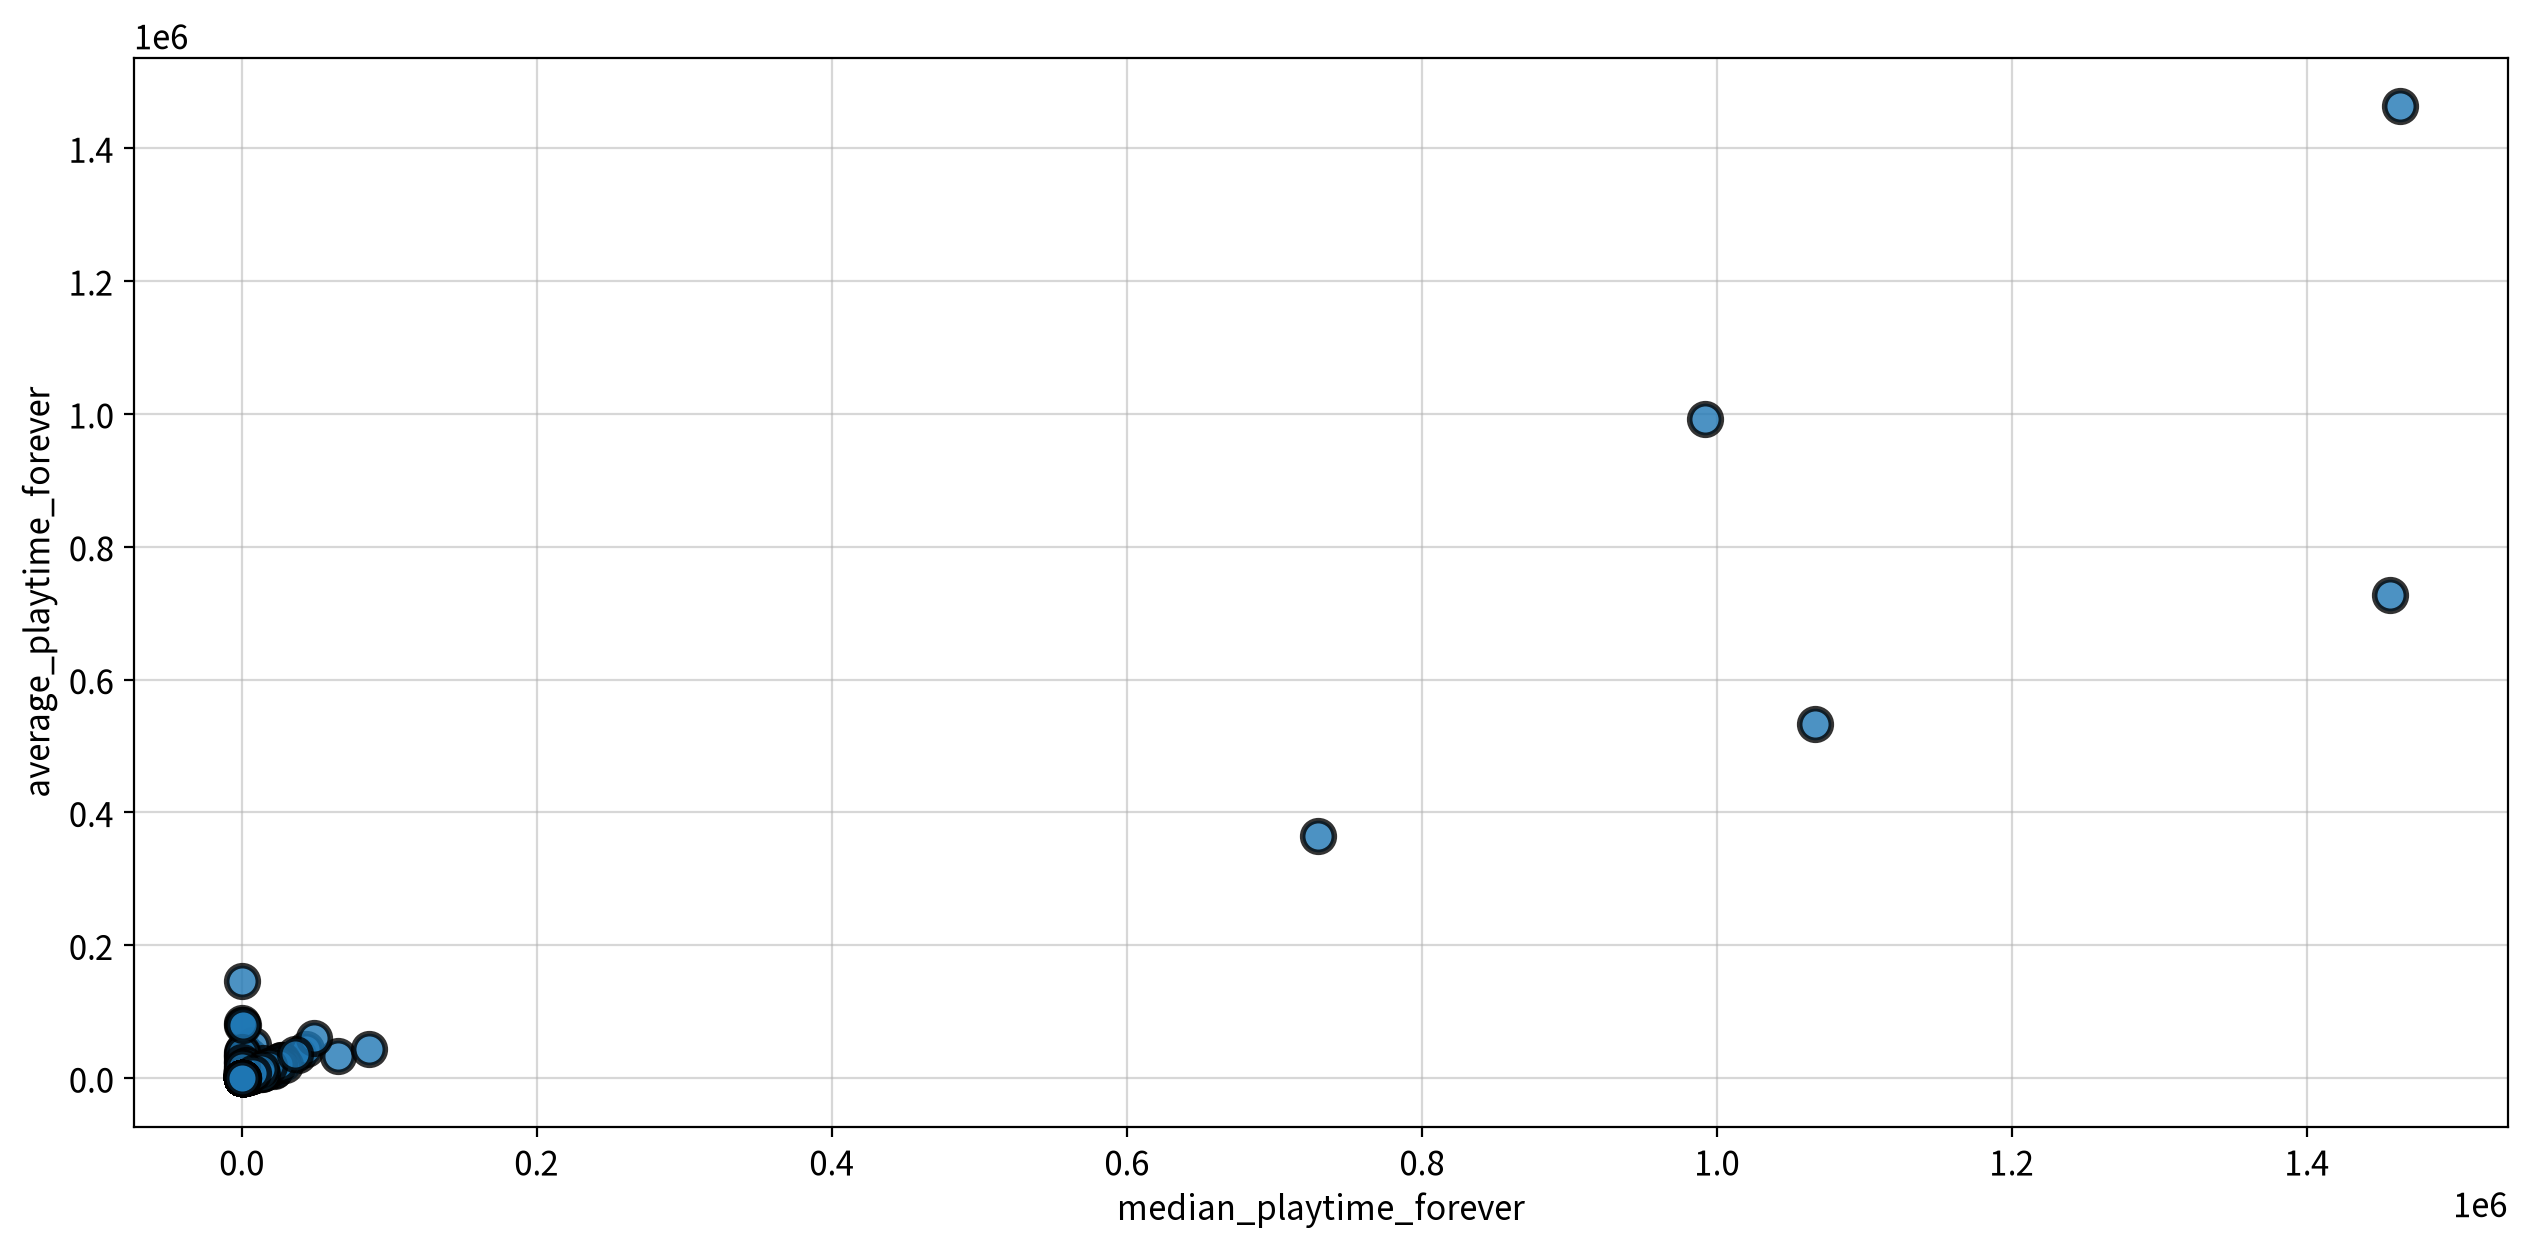

In [22]:
# 두 변수의 산점도 그리기
my_plot.scatterplot(data=playtime, x='median_playtime_forever',
                    y='average_playtime_forever', 
                    size=130, edgecolor="black", linewidth=2,
                    alpha=0.8)

- 두 플레이타임 변수의 최댓값이 약 146만 분에 달해, 일반적인 선형 축에서는 대부분의 데이터가 원점 부근에 밀집되어 나타났다.
> 이에 따라 극단적으로 큰 값의 시각적 영향을 완화하기 위해 로그 변환 필요성을 확인 후 변환한다.

In [23]:
# 로그 변환 사전 확인
my_qtcheck.numerical_summary(playtime)[['skew','kurt', 'log_need']]

,skew,kurt,log_need
median_playtime_forever,42.949595,1923.837690,log
average_playtime_forever,49.589662,2745.235984,log


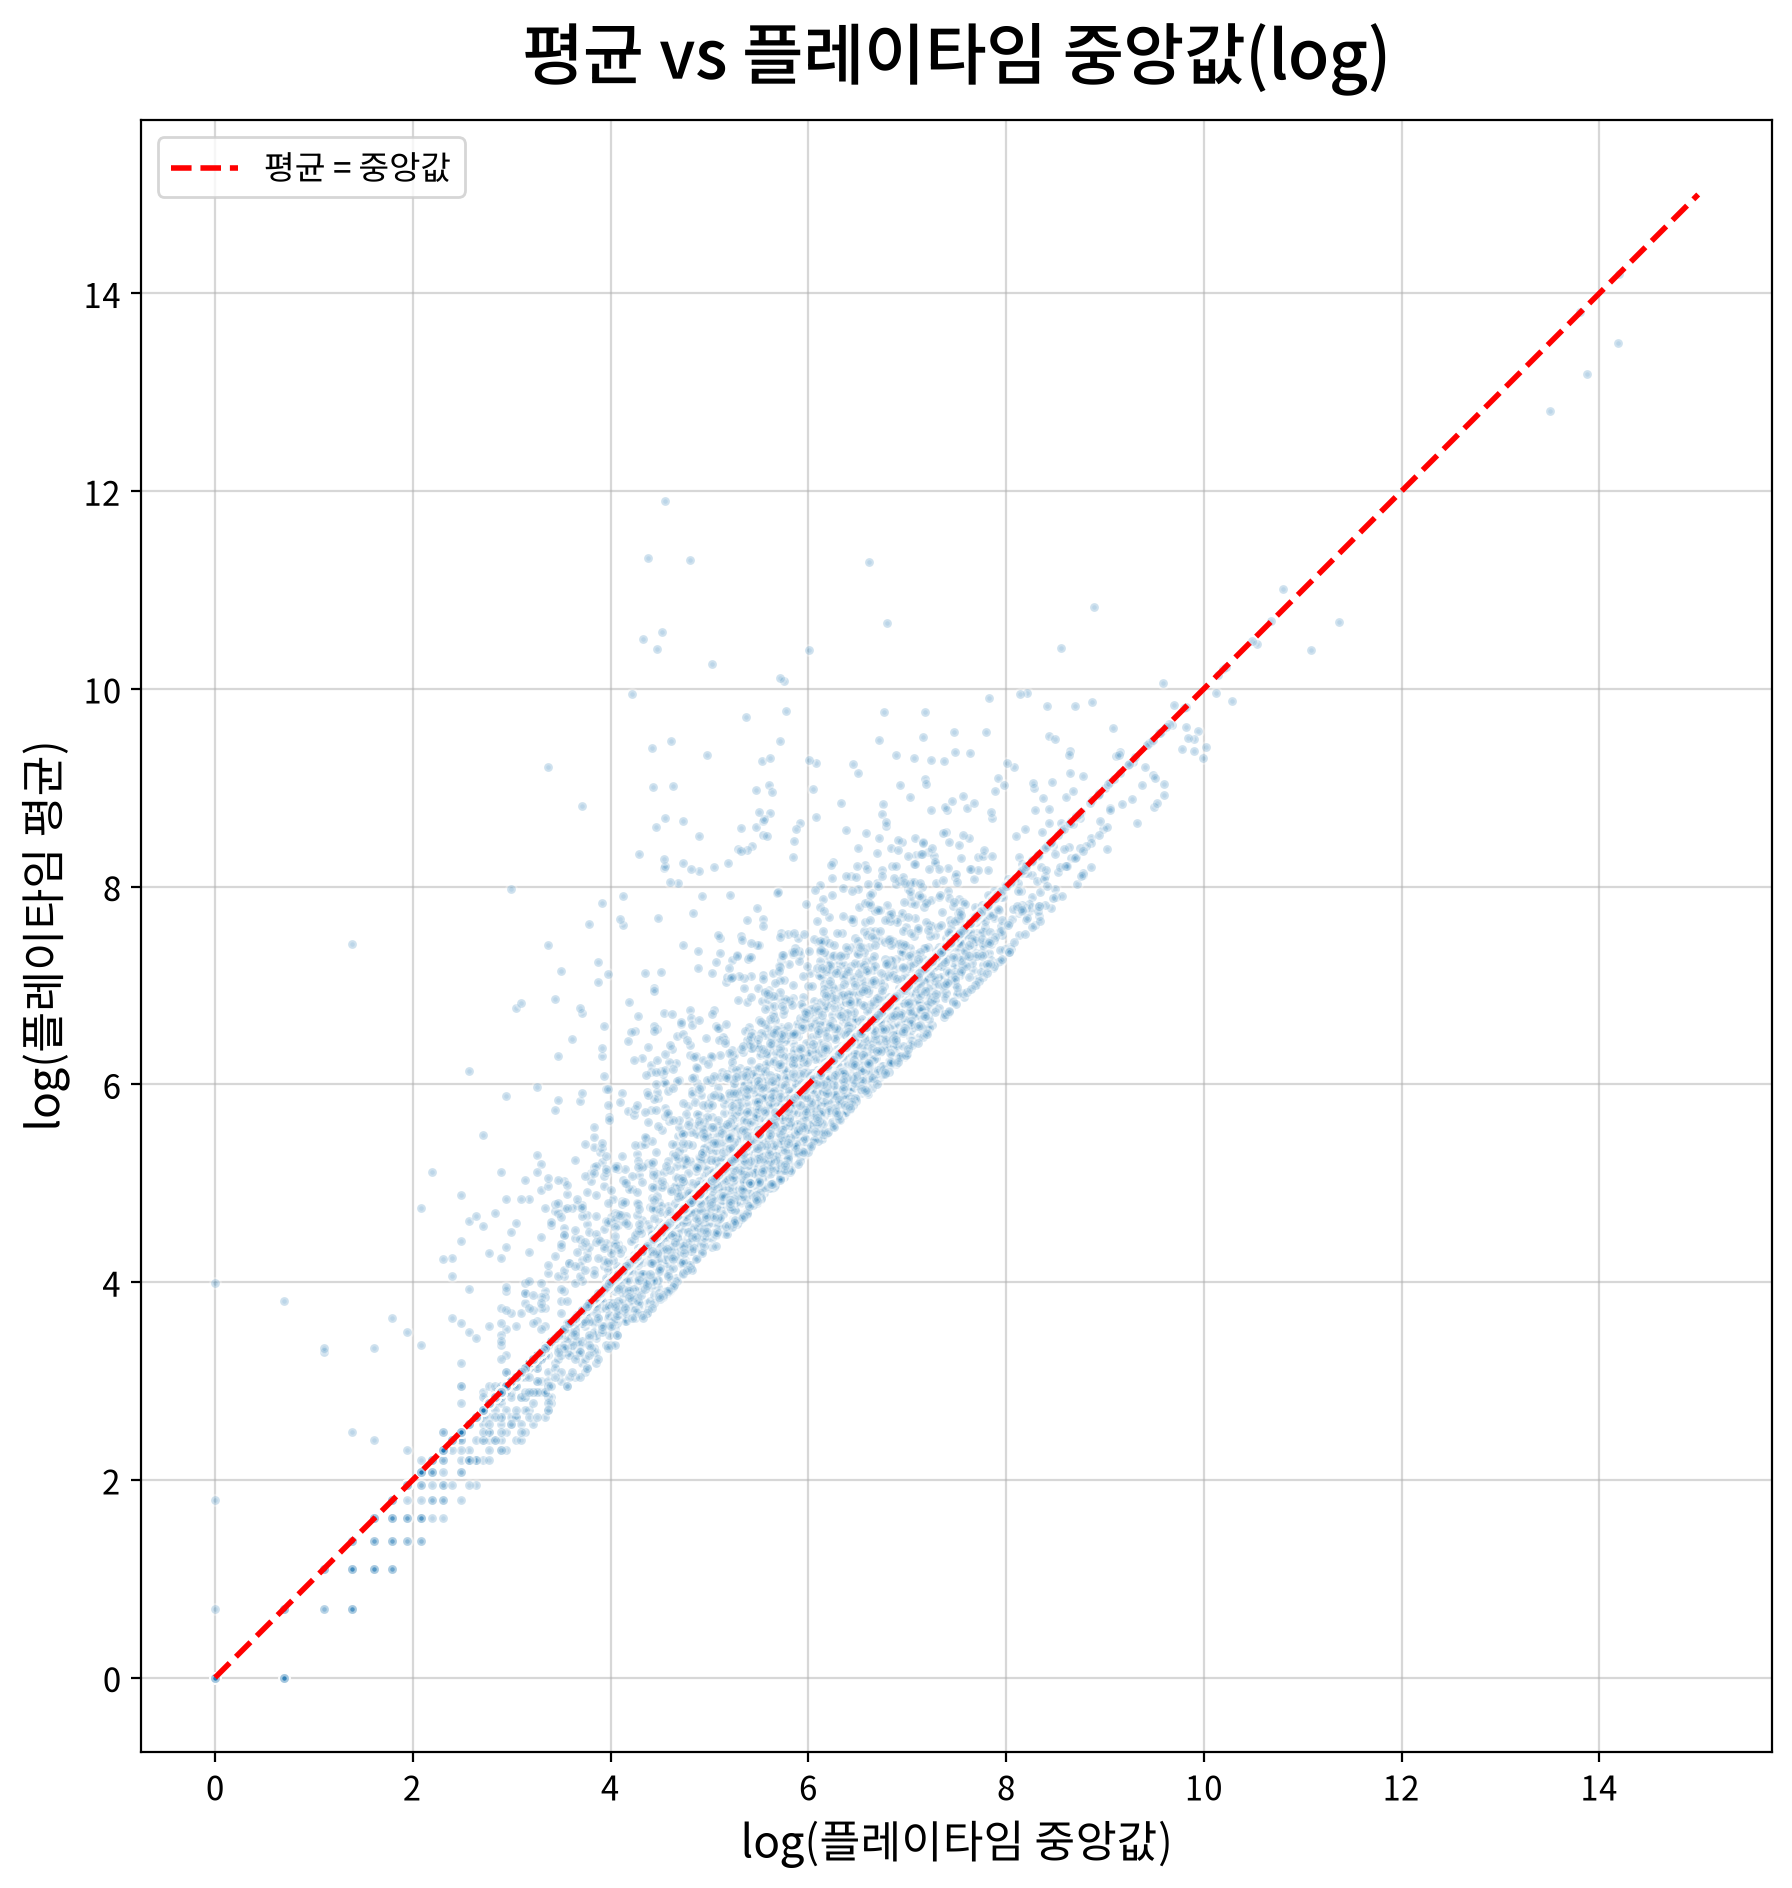

In [24]:
# 로그 변환 후 산점도 다시 그리기
playtime["log_average_playtime"] = np.log(playtime["average_playtime_forever"])
playtime["log_median_playtime"] = np.log(playtime["median_playtime_forever"])

fig, ax = my_plot.init(width=960, height=960, title='평균 vs 플레이타임 중앙값(log)',
                       xlabel='log(플레이타임 중앙값)', ylabel='log(플레이타임 평균)')

my_plot.scatterplot(data=playtime, x='log_median_playtime', y='log_average_playtime',
                    size=10, alpha=0.3, ax=ax)

ax.plot([0, 15], [0, 15], color='red', linestyle='--', label='평균 = 중앙값')
ax.set_aspect('equal', adjustable='box')
ax.legend()

my_plot.show()

- 두 플레이타임에 로그 변환을 적용하여 산점도를 시각화한 결과, 두 변수 사이에 뚜렷한 양의 관계가 관찰되었다.
- 다수의 게임에서 두 값이 유사하게 나타났으나, 일부 게임에서는 플레이타임 평균이 중앙값보다 상당히 높게 나타났다.
- 이는 게임에 따라 플레이타임 평균이 장시간 이용자의 영향을 받을 가능성을 시사한다.
> 따라서 두 지표의 차이를 정량적으로 분석한 후, 일반적인 이용자의 플레이타임을 대표하는 종속변수를 선정하고자 한다.

In [25]:
# 두 변수의 차이를 계산
playtime['playtime_diff'] = playtime['average_playtime_forever'] - playtime['median_playtime_forever']

p = 0
m = 0
z = 0

for v in playtime['playtime_diff']:
    if v == 0:
        z += 1
    elif v < 0:
        m += 1
    else:
        p += 1

print(f"평균과 중앙값이 동일한 게임 수: {z}")
print(f"평균이 중앙값보다 큰 게임 수 : {p}")
print(f"평균이 중앙값보다 작은 게임 수 : {m}")

평균과 중앙값이 동일한 게임 수: 3327
평균이 중앙값보다 큰 게임 수 : 1837
평균이 중앙값보다 작은 게임 수 : 2846


In [26]:
# 차이값(절댓값)의 기술통계량 확인
playtime['playtime_diff'].abs().describe()

count      8010.000000
mean        567.693508
std       11229.391799
min           0.000000
25%           0.000000
50%          12.000000
75%         109.000000
max      727900.000000
Name: playtime_diff, dtype: float64

In [27]:
# 원본 이름과 연결하여 차이가 큰 게임 확인
extreme_indices = playtime['playtime_diff'].abs().nlargest(10).index
display(df1.loc[extreme_indices, ['appid', 'name', 'median_playtime_forever',
                                'average_playtime_forever']])

,appid,name,median_playtime_forever,average_playtime_forever
6811,745960,A Sky Full of Stars 仰望夜空的星辰,1455841,727941
8582,332790,Darkness Assault,1066671,533442
11851,626510,LoveKami -Useless Goddess-,729457,364772
2937,899970,NEKOPARA Extra,95,146669
1912,1146630,Yokai's Secret,80,82588
1661,1406990,NEKOPARA Vol. 4,122,80800
2637,326480,If My Heart Had Wings,744,79441
256,39210,FINAL FANTASY XIV Online,7259,50259
21008,557190,BuildMoreCubes,86258,43283
2,570,Dota 2,898,43031


- 두 플레이타임이 모두 양수인 8,010개 게임 중 58.46%에서 평균과 중앙값이 서로 다르게 나타났다.
- 평균이 중앙값보다 큰 게임은 1,837개, 작은 게임은 2,846개, 같은 게임은 3,327개이다.
- 두 변수 차이의 절댓값 평균은 약 568분, 중앙값은 12분, 표준편차는 약 11,229.39분으로 나타났다.
> 두 변수 차이의 절댓값 중앙값은 12분으로 작지만, 일부 게임에서는 두 지표 간 상당한 차이가 발생한다는 것을 의미한다.
>
> 평균은 극단적으로 긴 플레이타임을 가진 이용자의 영향을 상대적으로 크게 받을 수 있는 반면, 중앙값은 이러한 극단값에 덜 민감하다.   
> 따라서 연구 목적과 두 변수의 분포 특성을 종합적으로 고려하여 `median_playtime_forever`를 최종 종속변수로 선정한다.

> 플레이타임 중앙값이 모두 양수인 게임만 분석 대상으로 했을 경우, 플레이타임 중앙값이 0인 약 90%의 데이터는 분석 대상에서 제외된다.   
> 이에 따라 대규모 데이터 제외로 인한 선택 편향이 발생할 가능성이 있으므로, 플레이타임 중앙값이 0인 게임과 양수인 게임의 주요 특성을 비교하고자 한다.   
> `가격`, `DLC 수`, `도전과제 수`, `장르` 등의 변수별 분포를 비교하여 두 집단 간 차이를 확인하고, 이를 바탕으로 플레이타임 중앙값 0값 제외의 타당성과 최종 분석 결과의 해석 범위를 검토한다.

In [28]:
# 플레이타임 중앙값이 0인 행과 아닌 행을 분류
df1_zero = df1.loc[df1['median_playtime_forever'] == 0]
df1_nonzero = df1.loc[df1['median_playtime_forever'] > 0]

# 게임 수 및 비율 비교
pd.DataFrame({'플레이타임 중앙값 구분': ['0인 게임', '양수인 게임', '전체'],
              '게임 수 (개)': [len(df1_zero), len(df1_nonzero), len(df1)],
              '비율 (%)': [len(df1_zero) / len(df1) * 100, len(df1_nonzero) / len(df1) * 100, 100]})

,플레이타임 중앙값 구분,게임 수 (개),비율 (%)
0,0인 게임,81608,91.062063
1,양수인 게임,8010,8.937937
2,전체,89618,100.000000


In [29]:
# 집단 비교에 사용할 수치형 변수
compare_columns = ['price', 'dlc_count', 'achievements', 'median_playtime_forever']

pd.concat([df1_zero[compare_columns].describe().round(2),
        df1_nonzero[compare_columns].describe().round(2)], 
        axis=1, keys=['플레이타임 0', '플레이타임 양수'])

플레이타임 0                                                플레이타임 양수  \
          price dlc_count achievements median_playtime_forever    price   
count  81608.00  81608.00     81608.00                 81608.0  8010.00   
mean       6.86      0.41        17.93                     0.0    11.85   
std       13.34     12.91       151.61                     0.0    12.39   
min        0.00      0.00         0.00                     0.0     0.00   
25%        0.99      0.00         0.00                     0.0     1.99   
50%        3.99      0.00         3.00                     0.0     8.99   
75%        9.99      0.00        18.00                     0.0    18.99   
max      999.98   3427.00      9821.00                     0.0    99.99   

                                                      
      dlc_count achievements median_playtime_forever  
count   8010.00      8010.00                 8010.00  
mean       2.50        47.27                 1283.92  
std       30.57       253.70                29433.63  
min        0.00         0.00                    1.00  
25%        0.00         2.00                   60.00  
50%        0.00        20.00                  213.00  
75%        1.00        41.00                  442.00  
max     2004.00      5000.00              1462997.00

In [30]:
# 집단 비교에 사용할 명목형 변수
# 누적 플레이타임 중앙값이 0인 게임 (제외 대상)
df_zero = steam_cleaned[steam_cleaned['median_playtime_forever'] == 0].copy()

# 누적 플레이타임 중앙값이 0보다 큰 게임 (분석 대상)
df_positive = steam_cleaned[steam_cleaned['median_playtime_forever'] > 0].copy()

compare_df = pd.concat([
    df_zero.assign(구분='제외 대상'),
    df_positive.assign(구분='분석 대상')
], ignore_index=True)

# 게임 수 확인
compare_df['구분'].value_counts()

구분
제외 대상    81608
분석 대상     8010
Name: count, dtype: int64

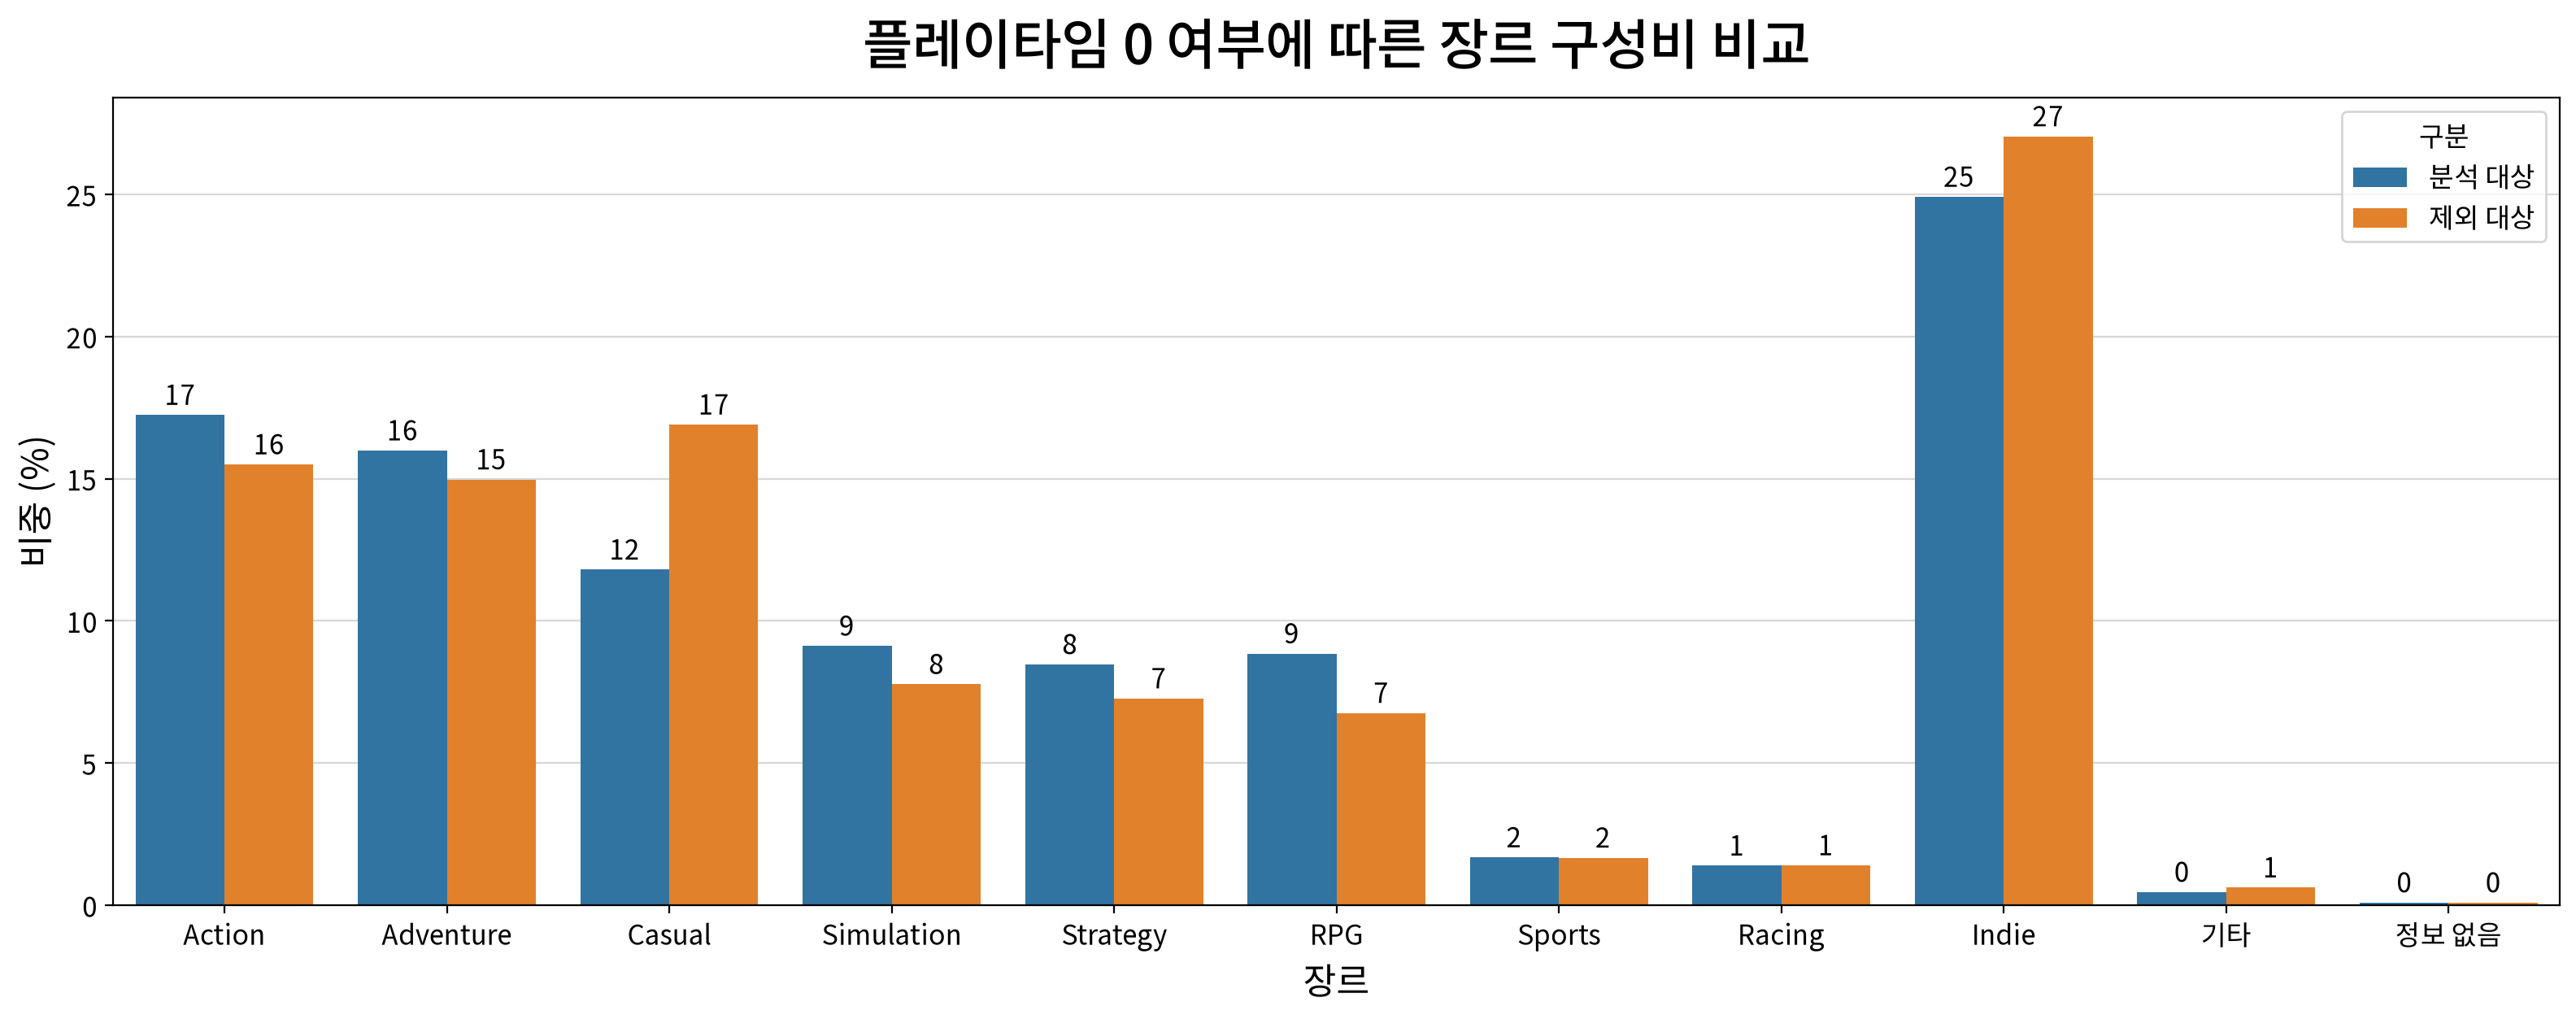

In [31]:
# 주요 장르
main_genres = [
    'Action', 'Adventure', 'Casual',
    'Simulation', 'Strategy', 'RPG',
    'Sports', 'Racing', 'Indie'
]

# 장르 문자열을 리스트로 변환
genre_df = compare_df[['구분', 'genres']].copy()

genre_df['장르'] = genre_df['genres'].fillna('[]').apply(
    lambda x: ast.literal_eval(x) if x.strip() else []
)

# 주요 9개 장르와 기타 분류
genre_df['장르'] = genre_df['장르'].apply(
    lambda x: [g for g in main_genres if g in x]
    or (['기타'] if x else ['정보 없음'])
)

# 복수 장르 분리
genre_df = genre_df.explode('장르')

# 집단별 장르 게임 수
genre_count = (
    genre_df.groupby(['구분', '장르'])
    .size()
    .reset_index(name='게임 수')
)

# 집단별 장르 구성비 (합계 약 100%)
genre_count['비중(%)'] = (
    genre_count['게임 수']
    / genre_count.groupby('구분')['게임 수'].transform('sum')
    * 100
).round(2)

# 장르 구성비 비교
my_plot.barplot(
    data=genre_count,
    x='장르',
    y='비중(%)',
    hue='구분',
    order=main_genres + ['기타', '정보 없음'],
    title='플레이타임 0 여부에 따른 장르 구성비 비교',
    xlabel='장르',
    ylabel='비중 (%)',
    width=1600,
    errorbar=None,
    text=True
)

- 플레이타임 중앙값이 0인 게임(81,608개, 91.06%)과 양수인 게임(8,010개, 8.94%)의 기술통계량을 비교한 결과, 가격·DLC 수·도전과제 수에서 차이가 확인되었다.
- 가격 중앙값은 각각 3.99달러와 8.99달러, 도전과제 수 중앙값은 3개와 20개로 나타나 플레이타임 중앙값 양수 집단에서 상대적으로 높은 값을 보였다.
- DLC 수는 두 집단 모두 중앙값이 0이었으나, 3사분위수는 각각 0개와 1개로 차이가 나타났다.
- 장르는 주요 9개 장르와 `기타`, `정보 없음`으로 구분하여 두 집단의 구성비를 비교하였다. 주요 9개 장르는 중복 집계를 허용하고, 해당 장르에 하나도 속하지 않는 게임은 `기타`, 장르 정보가 없는 게임은 `정보 없음`으로 분류하였다.
- 플레이타임 중앙값 양수 집단에서는 `Indie`(24.91%), `Action`(17.24%), `Adventure`(15.99%) 순으로 장르 집계 비중이 높게 나타났다. 장르별 구성비는 각 집단의 전체 장르 집계 건수를 기준으로 산출하여 두 집단의 장르 구성 차이를 비교하도록 하였다.

> 따라서 플레이타임 중앙값이 양수인 게임만 분석할 경우 상대적으로 가격이 높고 DLC 및 도전과제 수가 많은 게임의 특성이 더 크게 반영될 가능성이 있다.
>
> 또한 장르별 구성비를 비교한 결과, 플레이타임 중앙값이 0인 집단과 양수인 집단에서 장르 구성이 대체로 유사하나 Casual은 0 집단에서 더 높고 RPG·Simulation은 양수 집단에서 더 높다. 단, 복수 장르의 중복 집계를 허용하였으므로 구성비는 실제 게임 수가 아닌 장르 집계 건수를 기준으로 해석한다.
>
> 이러한 집단 간 특성 차이를 고려하여 플레이타임 중앙값이 0인 게임의 제외에 따른 선택 편향 가능성을 분석의 한계로 명시하고, 최종 분석을 진행한다.

#### 6. 출시일과 플레이타임 중앙값의 관계 확인

> 게임별 누적 플레이타임 중앙값은 출시 이후 경과한 기간의 영향을 받을 가능성이 있다.   
> 따라서 출시 이후 경과한 기간이 길 수록 게임별 플레이타임 중앙값이 높은지 연도 별로 확인하고자 한다.

In [32]:
# 필요한 컬럼 추출 후 출시일의 데이터 타입 확인
release_playtime = steam_cleaned[['appid', 'name', 'release_date', 'median_playtime_forever']]
release_playtime.info()

<class 'pandas.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   appid                    89618 non-null  int64
 1   name                     89618 non-null  str  
 2   release_date             89618 non-null  str  
 3   median_playtime_forever  89618 non-null  int64
dtypes: int64(2), str(2)
memory usage: 5.1 MB


In [33]:
# 출시일에서 연도만 추출
release_playtime['release_year'] = release_playtime['release_date'].astype('datetime64[ns]').dt.year
release_playtime.head()

,appid,name,release_date,median_playtime_forever,release_year
0,730,Counter-Strike 2,2012-08-21,5174,2012
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,2017
2,570,Dota 2,2013-07-09,898,2013
3,271590,Grand Theft Auto V Legacy,2015-04-13,7101,2015
4,359550,Tom Clancy's Rainbow Six® Siege,2015-12-01,2434,2015


In [34]:
# 플레이타임 중앙값이 0보다 큰 게임으로 제한
release_playtime = release_playtime[release_playtime['median_playtime_forever'] > 0]
release_playtime.head()

,appid,name,release_date,median_playtime_forever,release_year
0,730,Counter-Strike 2,2012-08-21,5174,2012
2,570,Dota 2,2013-07-09,898,2013
3,271590,Grand Theft Auto V Legacy,2015-04-13,7101,2015
4,359550,Tom Clancy's Rainbow Six® Siege,2015-12-01,2434,2015
7,252490,Rust,2018-02-08,3675,2018


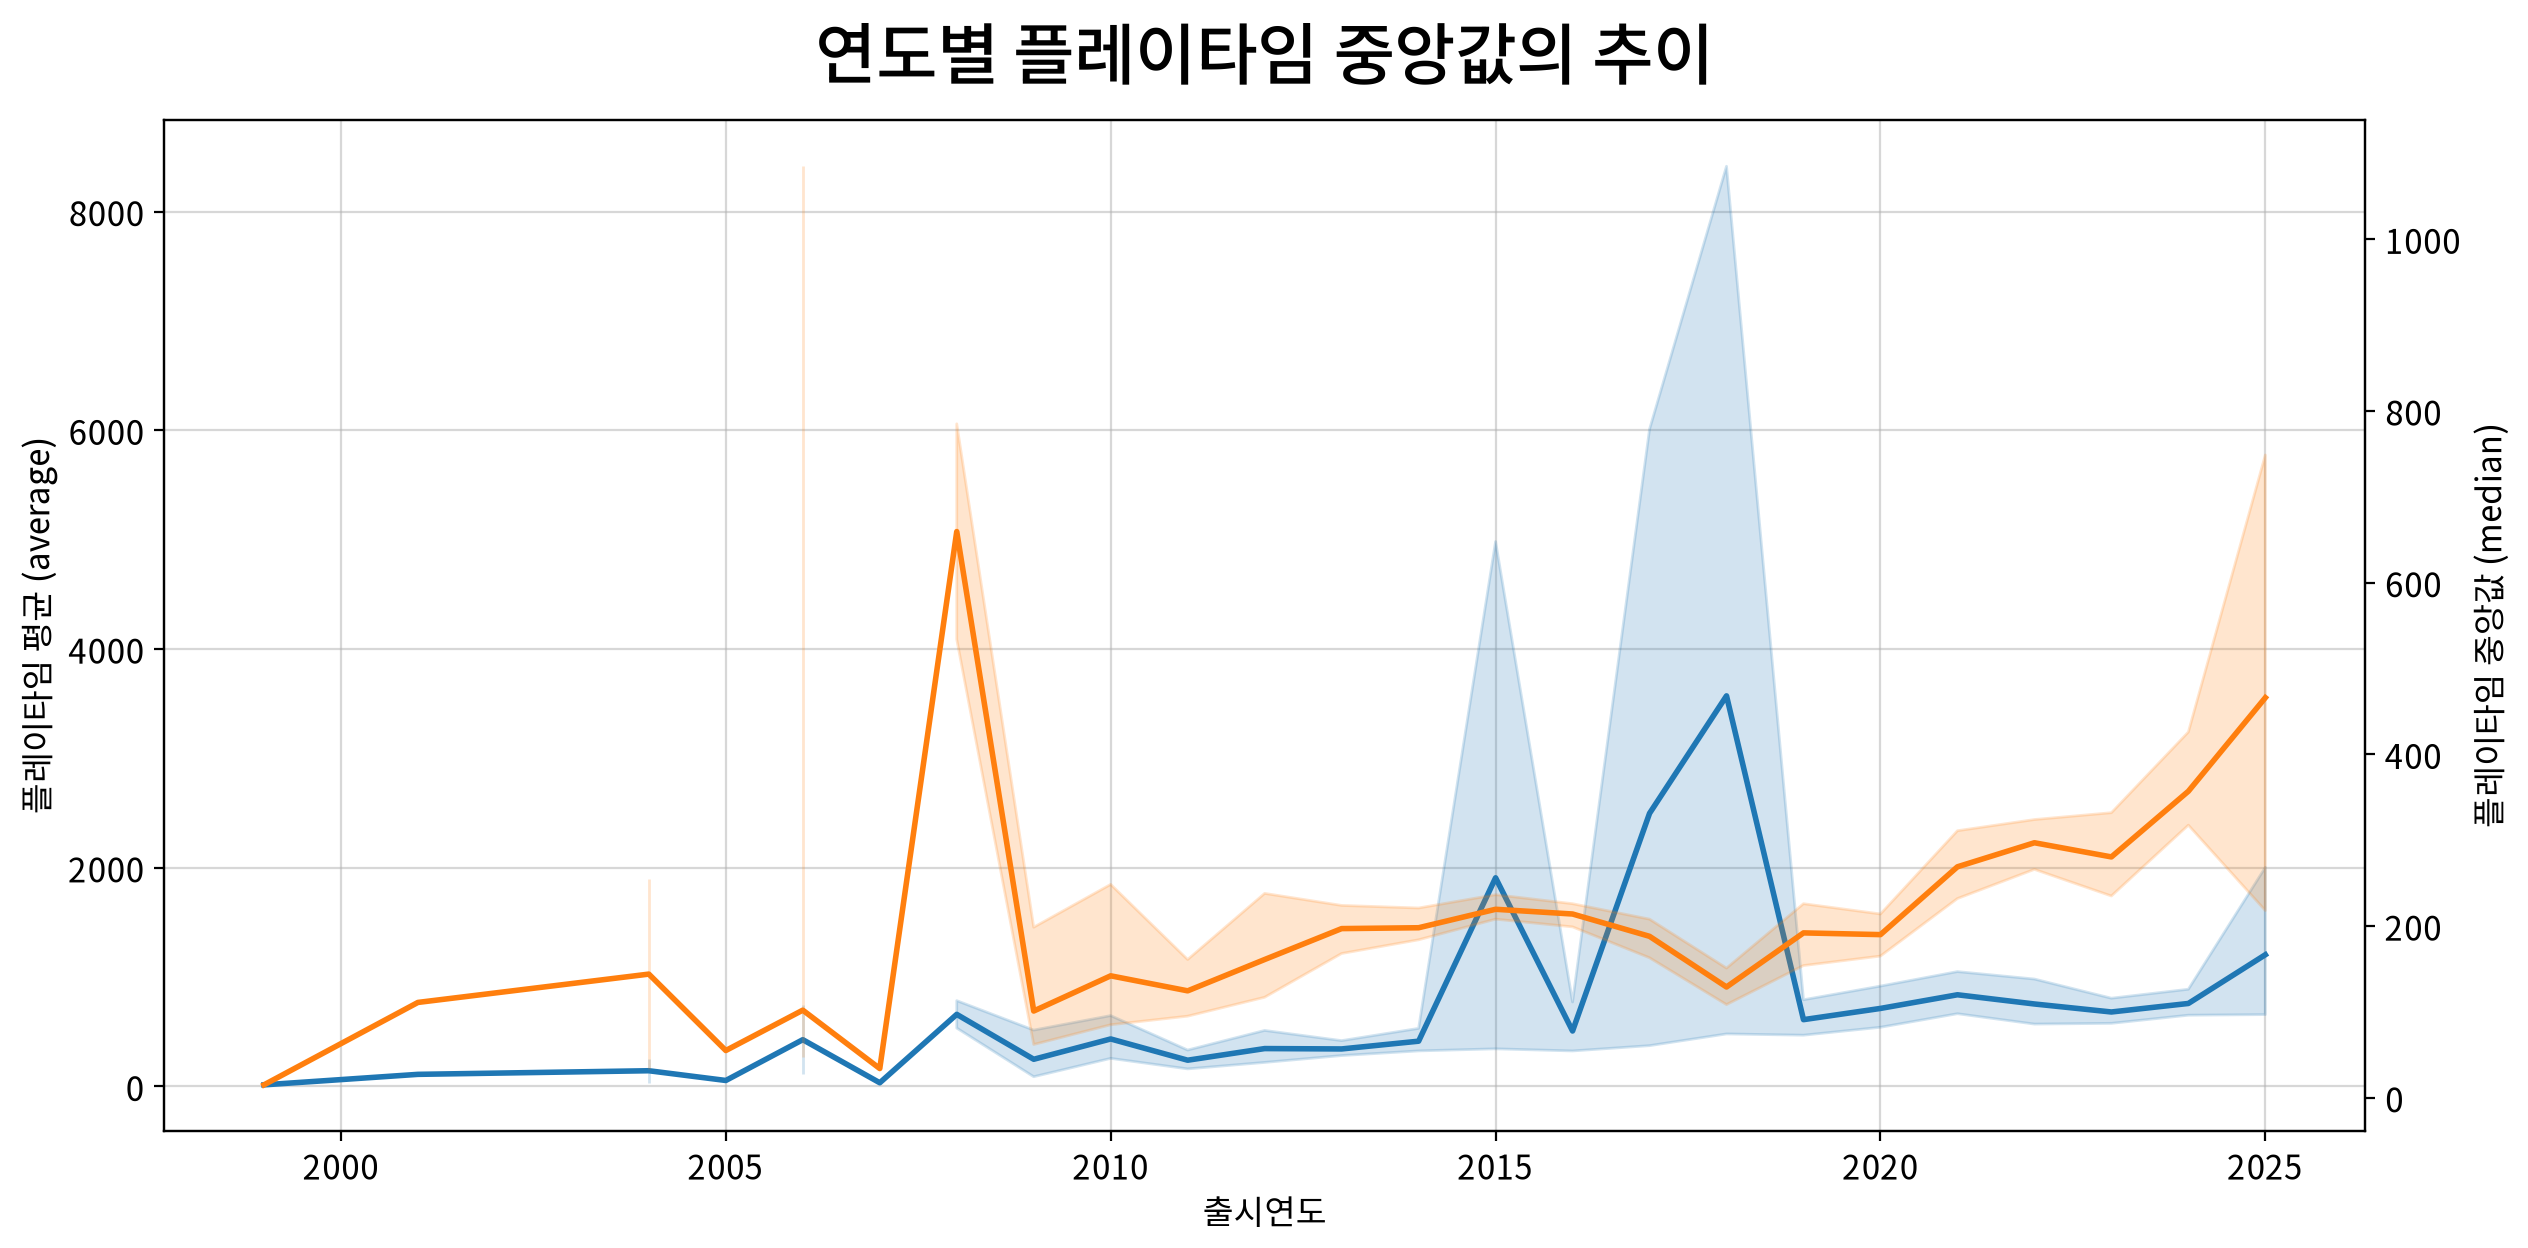

In [35]:
# 연도별 플레이타임 중앙값 확인
fig, ax = my_plot.init(title='연도별 플레이타임 중앙값의 추이', twinx=True)

my_plot.lineplot(data=release_playtime, x='release_year', y='median_playtime_forever',
                 color='tab:blue', ax=ax[0])
my_plot.lineplot(data=release_playtime, x='release_year', y='median_playtime_forever',
                 estimator=np.median, color='tab:orange', ax=ax[1])
ax[0].set_xlabel('출시연도')
ax[0].set_ylabel('플레이타임 평균 (average)')
ax[1].set_ylabel('플레이타임 중앙값 (median)')
my_plot.show()

- 출시 연도에 따른 누적 플레이타임 중앙값의 변화
    - 출시 연도별 플레이타임 중앙값을 비교한 결과, 오래된 게임일수록 누적 플레이타임이 길어지는 일관된 경향은 확인되지 않는다.
    - 오히려 최근 출시된 게임에서 연도별 중앙값이 상승하는 경향이 관찰되어, 단순히 출시 경과 기간이 길다는 이유만으로 플레이타임이 높아진다고 판단하기 어렵다.
- 연도별 평균과 중앙값의 차이
    - 일부 연도에서 게임별 플레이타임 중앙값의 평균이 중앙값보다 크게 나타나, 플레이타임이 긴 일부 게임이 평균을 높였을 가능성이 있다.
    - 특히 2017~2018년 부근에서 평균의 변동 폭과 신뢰구간이 크게 나타나 해당 연도 데이터의 분포 및 표본 규모에 대한 추가 확인이 필요하다.
> 현재 그래프에서는 출시 경과 기간과 누적 플레이타임 사이의 명확한 관계를 확인하기 어렵다.

### #03 변수별 값 분포 및 전처리 기준 점검

> 주요 변수의 값 분포를 확인하고 전처리 기준을 정하기 위해 다음 항목을 점검한다.

- ***가격*** (`price`): 무료 게임(가격이 0인 게임)의 수와 처리 방법, 가격대별 게임 수
- ***장르*** (`genres`): 장르 정보가 비어 있거나 여러 개인 게임 수, 분석 대상인 9개 장르에 속하지 않는 게임 수
- ***도전과제 수*** (`achievements`): 도전과제 개수 구간별 게임 수
- ***DLC*** (`dlc_count`): DLC 유무에 따른 게임 수

#### 1. 가격대

> 가격이 0인 게임은 무료로 별도 분류하고, 유료 게임은 아래와 같은 방법으로 가격대를 구분한다.

In [36]:
# 플레이타임 중앙값이 양수인 행만 필터링
df2 = df1.loc[df1['median_playtime_forever'] > 0].copy()

df2.head()

,appid,name,price,genres,dlc_count,achievements,median_playtime_forever,average_playtime_forever
0,730,Counter-Strike 2,0.00,"['Action', 'Free To Play']",1,1,5174,33189
2,570,Dota 2,0.00,"['Action', 'Strategy', 'Free To Play']",2,0,898,43031
3,271590,Grand Theft Auto V Legacy,0.00,"['Action', 'Adventure']",0,77,7101,19323
4,359550,Tom Clancy's Rainbow Six® Siege,3.99,['Action'],9,0,2434,14204
7,252490,Rust,39.99,"['Action', 'Adventure', 'Indie', 'Massively Mu...",4,92,3675,21195


In [37]:
# 게임 수가 비슷하도록 4개 구간으로 나누기
price = df2.loc[df2['price'] > 0, 'price']
price_group = pd.qcut(price, q=4, duplicates='drop')
price_group.value_counts().sort_index()

price
(0.489, 4.99]     2241
(4.99, 9.99]      1522
(9.99, 19.99]     2081
(19.99, 99.99]    1126
Name: count, dtype: int64

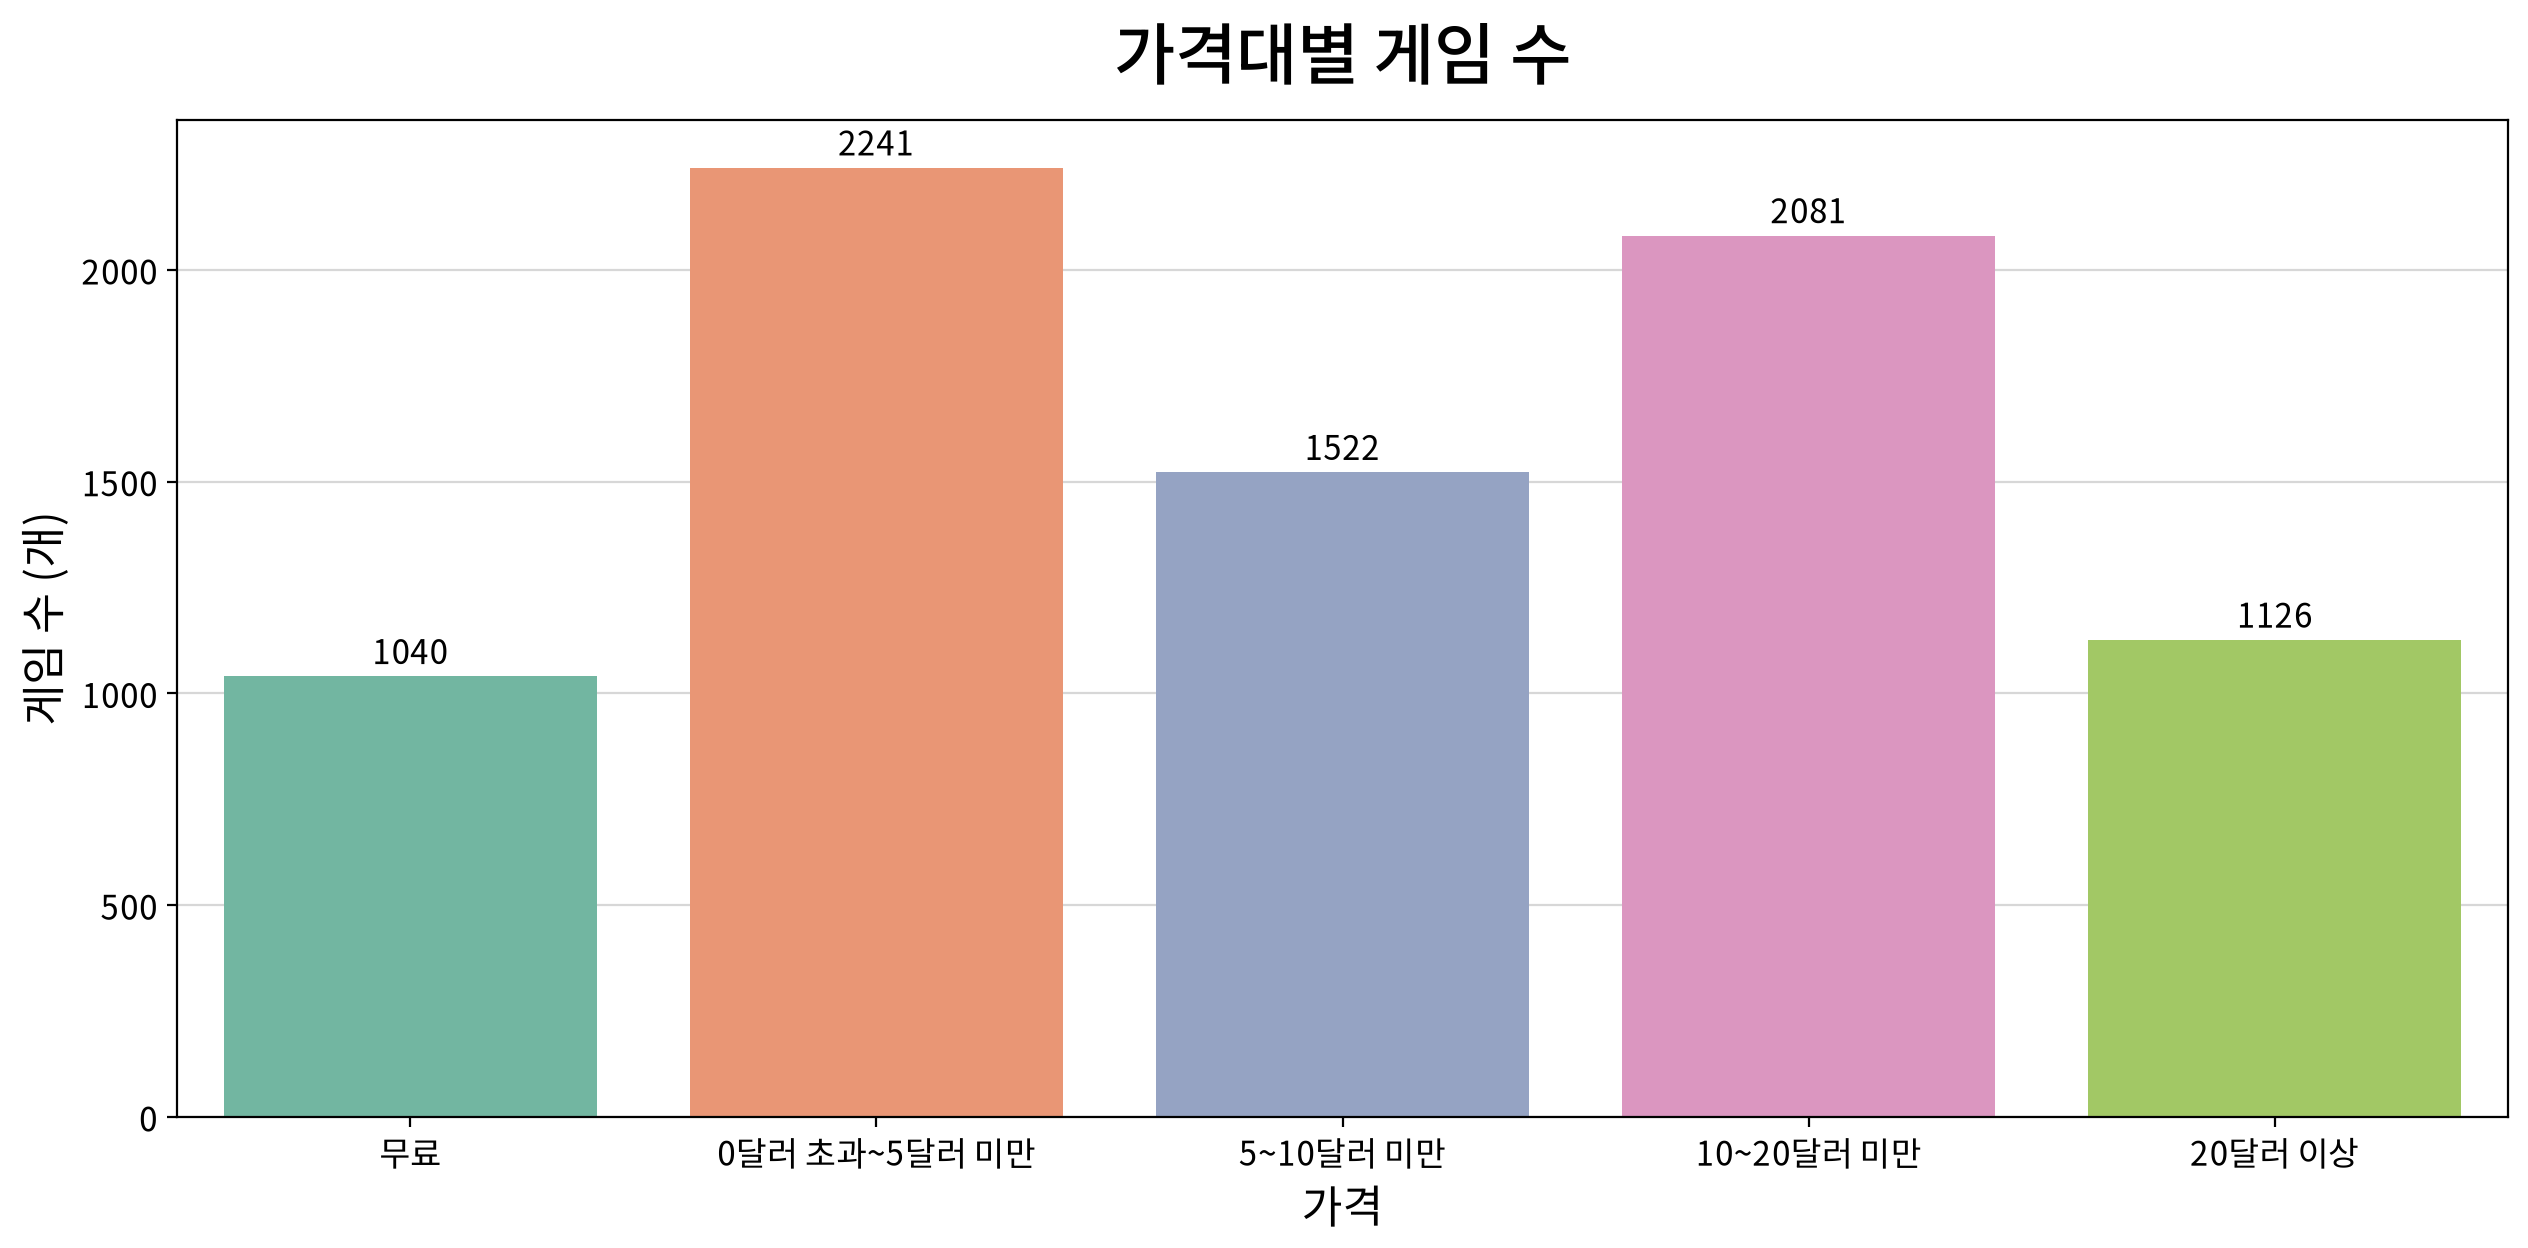

In [38]:
# 가격대 컬럼을 만들고 구간별 게임 수 확인
price = df2['price']
labels = ['무료', '0달러 초과~5달러 미만', '5~10달러 미만', '10~20달러 미만', '20달러 이상']
df2['가격대'] = np.select([price == 0, price < 5, price < 10, price < 20], labels[:4], default=labels[4])
df2['가격대'] = pd.Categorical(df2['가격대'], categories=labels, ordered=True)

my_plot.countplot(data=df2, x='가격대', palette='Set2', title='가격대별 게임 수',
xlabel='가격', ylabel='게임 수 (개)', text=True)

In [39]:
df2.info()

<class 'pandas.DataFrame'>
Index: 8010 entries, 0 to 88392
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   appid                     8010 non-null   int64   
 1   name                      8010 non-null   str     
 2   price                     8010 non-null   float64 
 3   genres                    8010 non-null   str     
 4   dlc_count                 8010 non-null   int64   
 5   achievements              8010 non-null   int64   
 6   median_playtime_forever   8010 non-null   int64   
 7   average_playtime_forever  8010 non-null   int64   
 8   가격대                       8010 non-null   category
dtypes: category(1), float64(1), int64(5), str(2)
memory usage: 967.1 KB


> - 무료 게임은 유료 게임과 구분하여 별도 범주로 설정한다.
> - 기존에 계획한 가격대의 여섯 구간보다 해석하기 용이한 다섯 구간으로 구분 기준을 바꾼다. 
>     - 최종 구간별 게임 수를 확인한 결과 각 구간에 약 1,000개 이상의 게임이 포함되어 있어, 가격대별 특성을 비교하기 위한 기준으로 채택하였다.
>     - 초기 계획에서는 게임 가격에 대한 도메인 지식을 바탕으로 무료, 10달러 미만, 10~20달러 미만, 20~30달러 미만, 30~60달러 미만, 60달러 이상의 6개 구간을 설정했다.
>     - 이후 실제 데이터 분포를 반영하기 위해 유료 게임(price > 0)을 대상으로 pd.qcut(q=4)을 적용하여 사분위수 경계와 구간별 게임 수를 확인하였다.
>     - 이를 참고하여 최종 가격 구간을 무료, 0달러 초과~5달러 미만, 5~10달러 미만, 10~20달러 미만, 20달러 이상의 5개 구간으로 변경하였다.
>     - 초기 검토에 사용했던 경계는 도메인 지식에 기반한 기준으로, 사분위수 분석 결과를 참고하여 구간을 재설정하면서 제외한다.
> - 가격대 구간
>     - `무료`
>     - `0달러 초과~5달러 미만`
>     - `5~10달러 미만`
>     - `10~20달러 미만`
>     - `20달러 이상`

#### 2. 도전과제 구간

> 도전과제 유무와 개수에 따른 게임 분포를 확인하기 위해, 도전과제가 없는 게임은 별도로 구분하고 나머지 게임들의 분포를 확인한다.

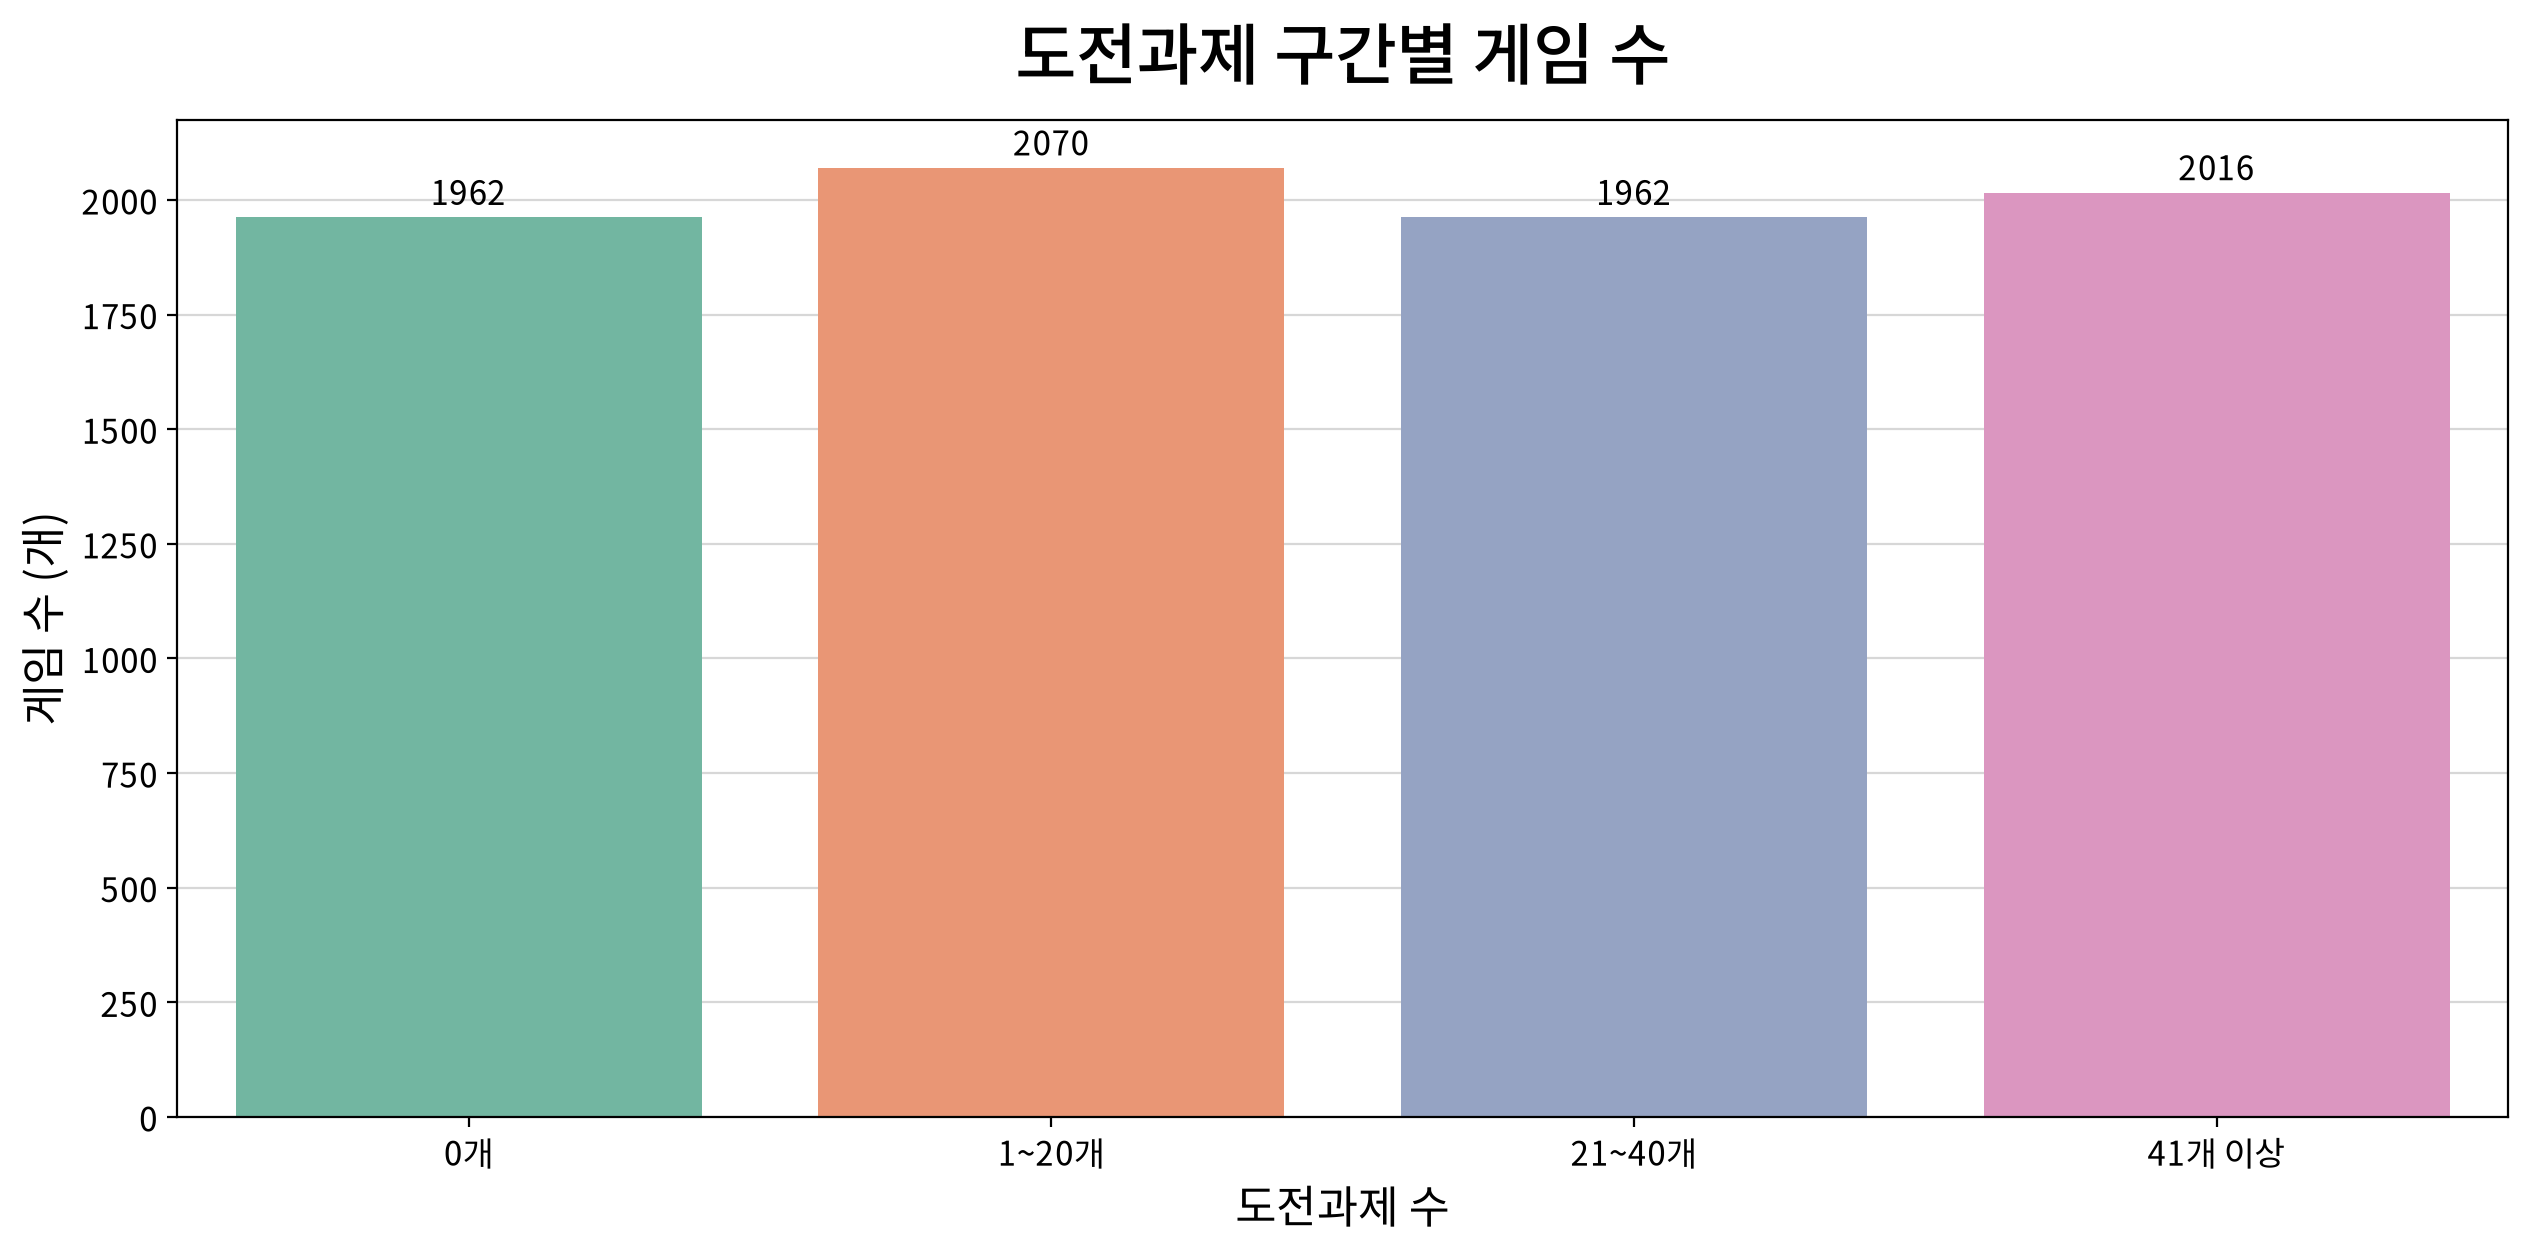

In [40]:
# 도전과제 구간별 게임 수 막대그래프 그리기
achievements = df2['achievements']
labels = ['0개', '1~20개', '21~40개', '41개 이상']
df2['도전과제'] = pd.cut(df2['achievements'], labels=labels, bins=[-1, 0, 20, 40, np.inf])
my_plot.countplot(data=df2, x='도전과제', palette='Set2', title='도전과제 구간별 게임 수',
xlabel='도전과제 수', ylabel='게임 수 (개)', text=True)

> 도전과제를 위 구간으로 나누어 확인한 결과, 구간별 게임 수가 비교적 고르게 분포하였다. 따라서 해당 구간을 도전과제 개수에 따른 게임 특성을 비교하기 위한 기준으로 사용한다. 도전과제는 `0개`, `1~20개`, `21~40개`, `41개 이상`으로 구분한다. 
>
> - 도전과제 개수 구간
>     - `0개`
>     - `1~20개`
>     - `21~40개`
>     - `41개 이상`

#### 3. DLC 유무

> DLC 유무에 따른 게임 분포를 확인하기 위해, DLC 개수가 0개인 게임은 `없음`, 1개 이상인 게임은 `있음`으로 구분하고 각 그룹의 게임 수를 확인한다.

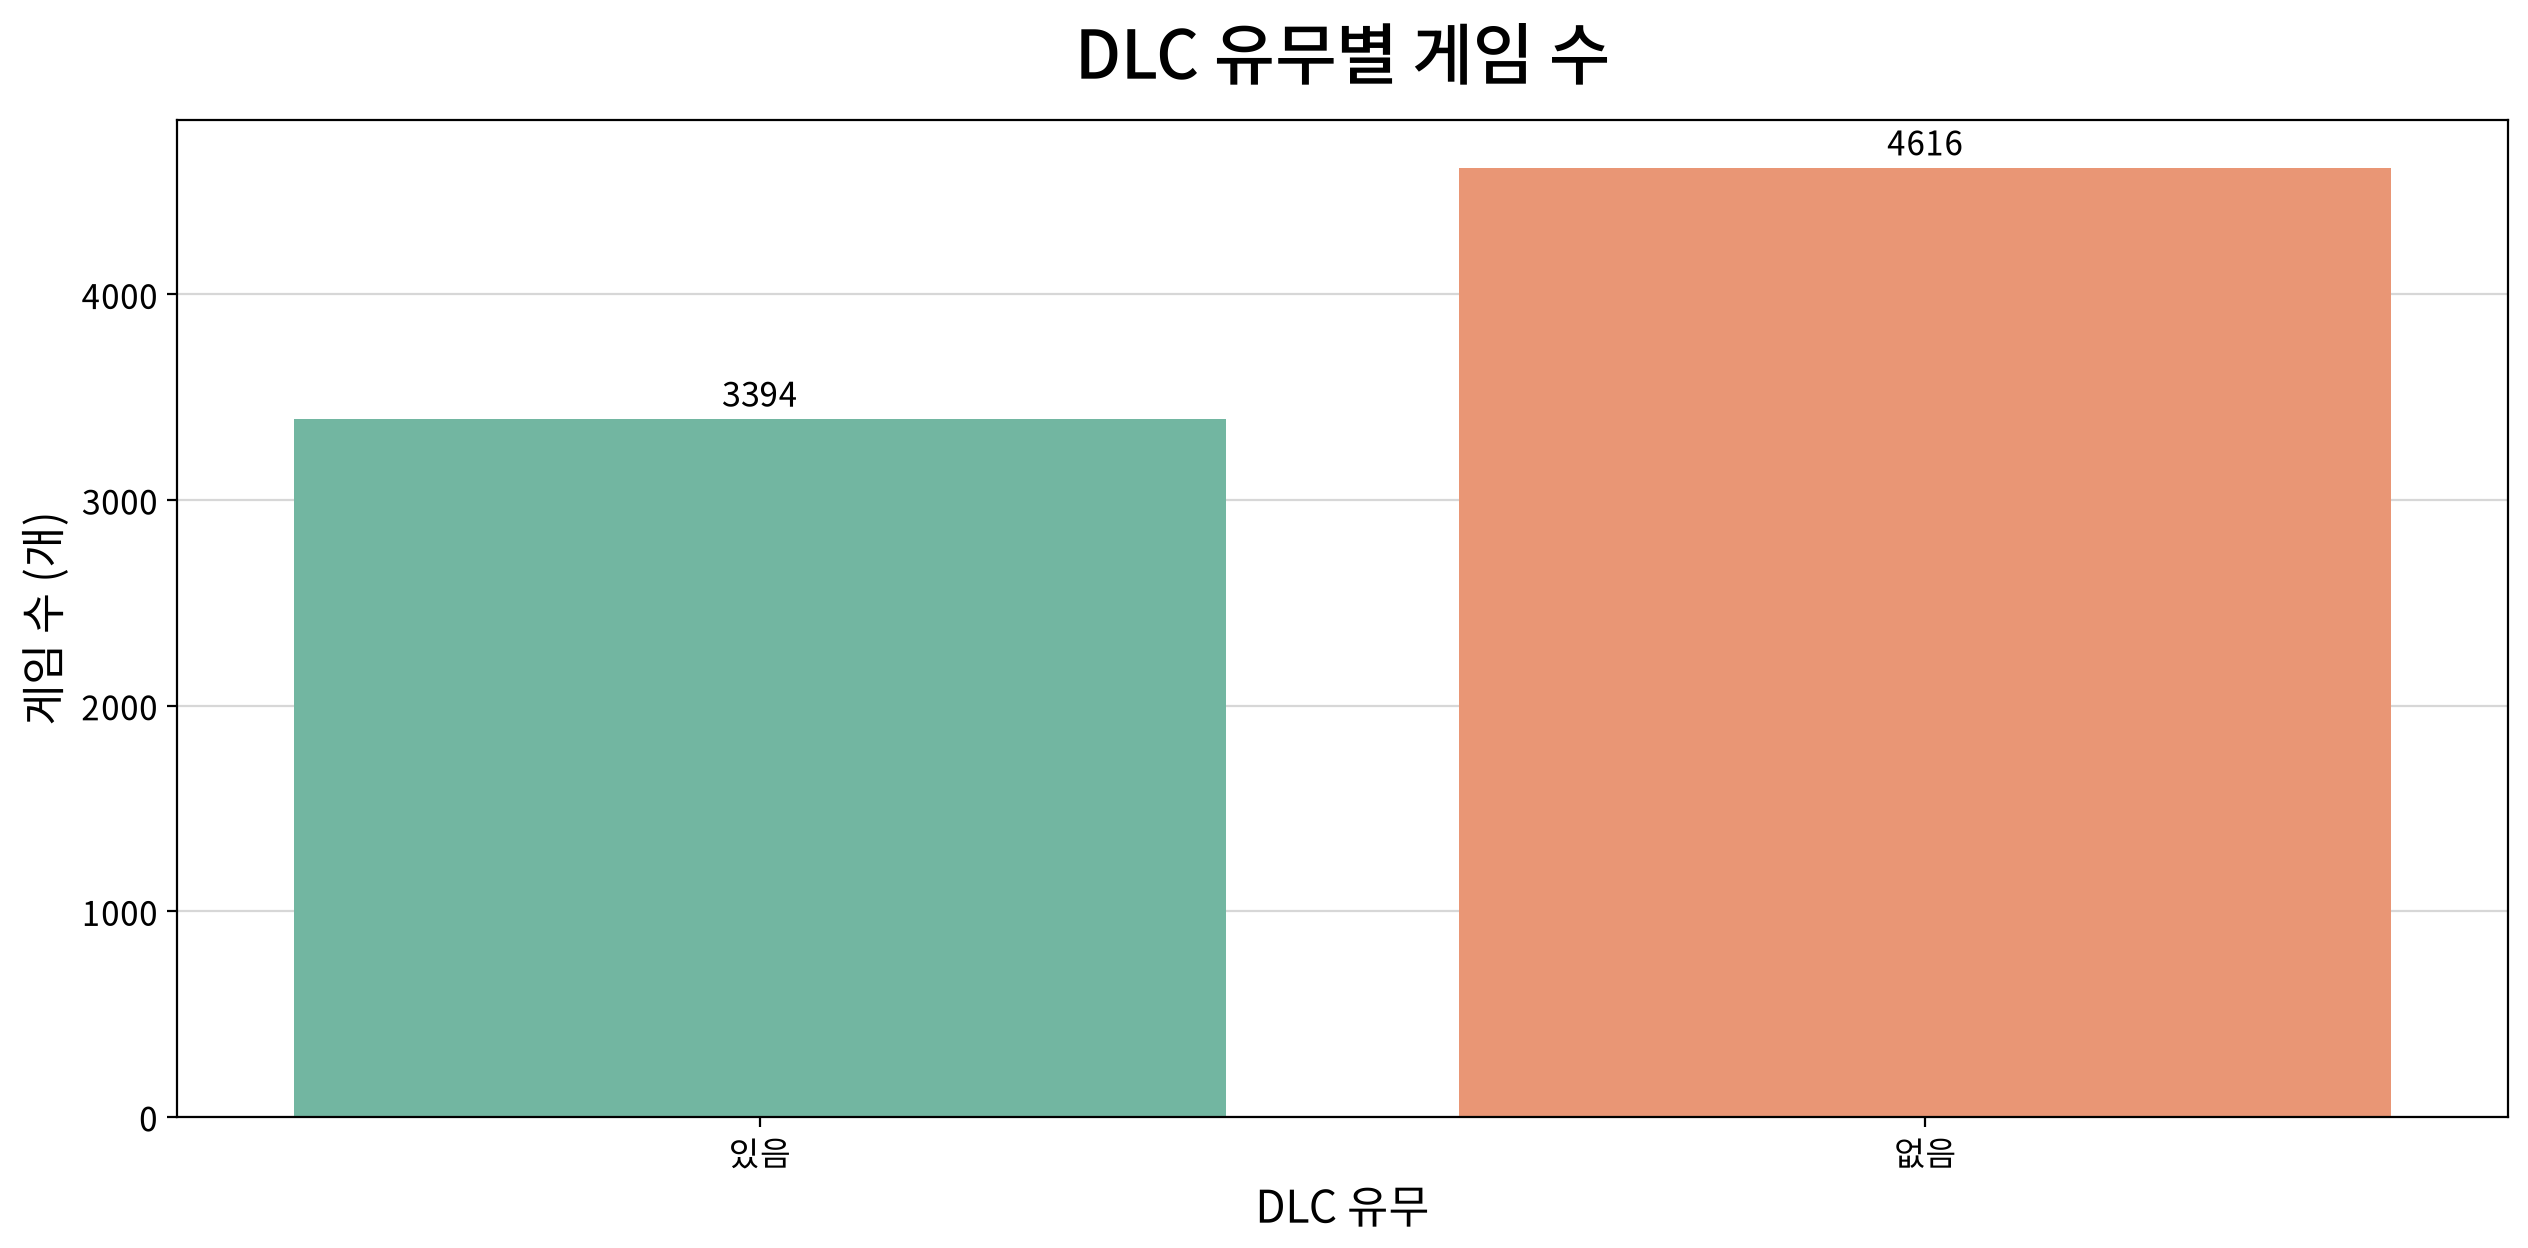

In [41]:
DLC = df2['dlc_count']
labels = ['있음', '없음']
df2['DLC'] = np.where(df2['dlc_count'] > 0, '있음', '없음')
df2['DLC'] = pd.Categorical(df2['DLC'], categories=labels, ordered=True)
my_plot.countplot(data=df2, x='DLC', palette='Set2', title='DLC 유무별 게임 수',
                  xlabel='DLC 유무', ylabel='게임 수 (개)', text=True)

- DLC 유무별 게임 수를 확인한 결과, DLC가 없는 게임이 있는 게임보다 많았다.
> 두 그룹 모두 다수의 게임이 포함(`있음` 3,394개, `없음` 4,616개)되어 있으며, 이후 분석에서는 `있음`과 `없음`으로 구분하여 게임 특성을 비교한다.
> 
>- DLC 유무
>   - `있음`
>   - `없음`


#### 4. 장르 구분

> 게임별 대표 장르를 선정할 수 있는지 판단하기 위해 장르 목록의 배열 순서를 점검한다. 

In [42]:
# 결측값이 아닌 첫 장르 값의 타입 확인
type(df2['genres'].dropna().iloc[0])

str

In [43]:
# 분석 대상의 장르 리스트 추출
analysis_genres = genre_lists.loc[df2.index]

# 장르 순서와 첫 번째 장르 확인
genre_check = df2[['name', 'genres']].copy()

genre_check['첫 번째 장르'] = analysis_genres.apply(
    lambda x: x[0] if x else None
)

genre_check['알파벳순 여부'] = analysis_genres.apply(
    lambda x: x == sorted(x)
)

# 복수 장르 게임만 확인
multi_genre = analysis_genres.apply(len) > 1

genre_check.loc[multi_genre].head(20)

,name,genres,첫 번째 장르,알파벳순 여부
0,Counter-Strike 2,"['Action', 'Free To Play']",Action,True
2,Dota 2,"['Action', 'Strategy', 'Free To Play']",Action,False
3,Grand Theft Auto V Legacy,"['Action', 'Adventure']",Action,True
7,Rust,"['Action', 'Adventure', 'Indie', 'Massively Mu...",Action,True
8,Garry's Mod,"['Casual', 'Indie', 'Simulation']",Casual,True
9,Apex Legends™,"['Action', 'Adventure', 'Free To Play']",Action,True
12,ELDEN RING,"['Action', 'RPG']",Action,True
13,Stardew Valley,"['Indie', 'RPG', 'Simulation']",Indie,True
16,Baldur's Gate 3,"['Adventure', 'RPG', 'Strategy']",Adventure,True
19,Destiny 2,"['Action', 'Adventure', 'Free To Play']",Action,True


In [44]:
# 장르의 알파벳순 여부 확인
genre_check.loc[multi_genre, '알파벳순 여부'].value_counts()

알파벳순 여부
True     6022
False     838
Name: count, dtype: int64

- 대부분 게임의 장르가 알파벳순으로 되어 있다.
> 첫 번째 장르를 대표 장르로 해석할 근거가 부족하며, 임의로 대표 장르를 선정할 경우 분석자의 주관이 개입될 수 있다.   
> 따라서 특정 장르를 임의로 선택하지 않고, 각 게임에 부여된 장르를 함께 반영하는 `다중 핫 인코딩`을 적용한다.   
> 이 방식에서는 하나의 게임이 여러 장르에 중복 포함되므로 장르별 게임 수의 합이 전체 게임 수보다 클 수 있다.

In [45]:
# 분석 대상의 장르 리스트 추출
genre_list = genre_lists.loc[df2.index]

# 장르별 열 생성: 해당하면 1, 아니면 0
genre_encoded = genre_list.str.join('|').str.get_dummies(sep='|')

genre_encoded.head()

,Accounting,Action,Adventure,Animation & Modeling,Audio Production,Casual,Design & Illustration,Early Access,Education,Free To Play,...,Racing,Sexual Content,Simulation,Software Training,Sports,Strategy,Utilities,Video Production,Violent,Web Publishing
0,0,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
3,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [46]:
# 장르별 게임 수: 각 열의 1 개수 합산
genre_counts = (
    genre_encoded.sum()
    .sort_values(ascending=False)
    .to_frame(name='게임 수')
)

genre_counts

,게임 수
Indie,5263
Action,3643
Adventure,3378
Casual,2494
Simulation,1926
RPG,1869
Strategy,1790
Free To Play,685
Early Access,524
Sports,355


> `Free To Play`, `Early Access`, `Massively Multiplayer`는 각각 무료 제공 방식, 사전 출시 상태, 플레이 방식을 나타내므로 메인 장르 선정에서 제외한다.
> 나머지 항목 중 게임 수가 많은 상위 9개 장르를 분석 대상으로 선정하고, 이 중 어느 메인 장르에도 해당하지 않는 게임은 `기타`로 분류하되 장르의 빈 값을 확인한다.

In [47]:
# 게임별 장르 수 확인
condlist = [genre_encoded.sum(axis=1)==0, genre_encoded.sum(axis=1)==1, genre_encoded.sum(axis=1)>1]
choicelist = ["장르 미지정 게임", "단일 장르 게임", "복수 장르 게임"]
pd.Series(np.select(condlist, choicelist, default="미분류")).value_counts().to_frame()

,count
복수 장르 게임,6860
단일 장르 게임,1130
장르 미지정 게임,20


> 복수 장르 게임은 6,860개이며, 장르 정보가 비어 있는 게임은 20개이다.   
> 장르 미지정 게임의 처리 기준을 결정하기 위해 해당 게임을 확인하였다.

In [48]:
# 장르 미지정 게임 확인
df2.loc[genre_encoded.sum(axis=1)==0]

,appid,name,price,genres,dlc_count,achievements,median_playtime_forever,average_playtime_forever,가격대,도전과제,DLC
873,955900,Amazing Cultivation Simulator,24.99,[],2,408,1438,4060,20달러 이상,41개 이상,있음
1976,1292940,Cube Escape Collection,4.99,[],0,72,364,345,0달러 초과~5달러 미만,41개 이상,없음
2293,1347430,Cute Honey,1.99,[],0,16,57,81,0달러 초과~5달러 미만,1~20개,없음
2396,559210,Rakuen,14.99,[],2,15,442,394,10~20달러 미만,1~20개,있음
2759,1094780,Fisher Online,13.99,[],3,13,2702,2702,10~20달러 미만,1~20개,있음
3136,667720,Red Faction Guerrilla Re-Mars-tered,19.99,[],1,57,117,188,10~20달러 미만,41개 이상,있음
3794,2015240,Dwarven Realms,6.69,[],0,27,1811,1009,5~10달러 미만,21~40개,없음
4884,1605010,Adorable Witch,1.57,[],1,16,29,156,0달러 초과~5달러 미만,1~20개,있음
5231,1471200,YUME,2.99,[],1,9,150,127,0달러 초과~5달러 미만,1~20개,있음
6965,1740000,Cute Honey: Bunny Girl,4.99,[],1,30,119,119,0달러 초과~5달러 미만,21~40개,있음


> 전체 분석 대상 8,010개 게임 중 장르 정보가 빈 리스트(`[]`)로 기록된 게임이 20개(약 0.25%) 확인되어 장르별 가격대와 플레이타임 중앙값 관계 분석에서 제외한다.

In [49]:
# 선정한 주요 장르
main_genres = [
    'Indie', 'Action', 'Adventure', 'Casual',
    'Simulation', 'RPG', 'Strategy', 'Sports', 'Racing'
]

# 선정한 9개 장르만 추출
genre_top10 = genre_counts.loc[main_genres].copy()

# 선정한 9개 장르에 속하지 않는 게임 확인
other = (
    (genre_encoded[main_genres].sum(axis=1) == 0)
    & (genre_encoded.sum(axis=1) > 0)
)

# 기타 게임 수 추가
genre_top10.loc['기타', '게임 수'] = other.sum()

# 기존 데이터에 장르 컬럼 추가
df2 = pd.concat([df2,
           genre_encoded[main_genres],
           other.astype(int).rename("기타")], axis=1)

# 그래프용 데이터프레임 생성
genre_summary = genre_top10.reset_index().rename(columns={'index': '장르'})
genre_summary

,장르,게임 수
0,Indie,5263.0
1,Action,3643.0
2,Adventure,3378.0
3,Casual,2494.0
4,Simulation,1926.0
5,RPG,1869.0
6,Strategy,1790.0
7,Sports,355.0
8,Racing,293.0
9,기타,97.0


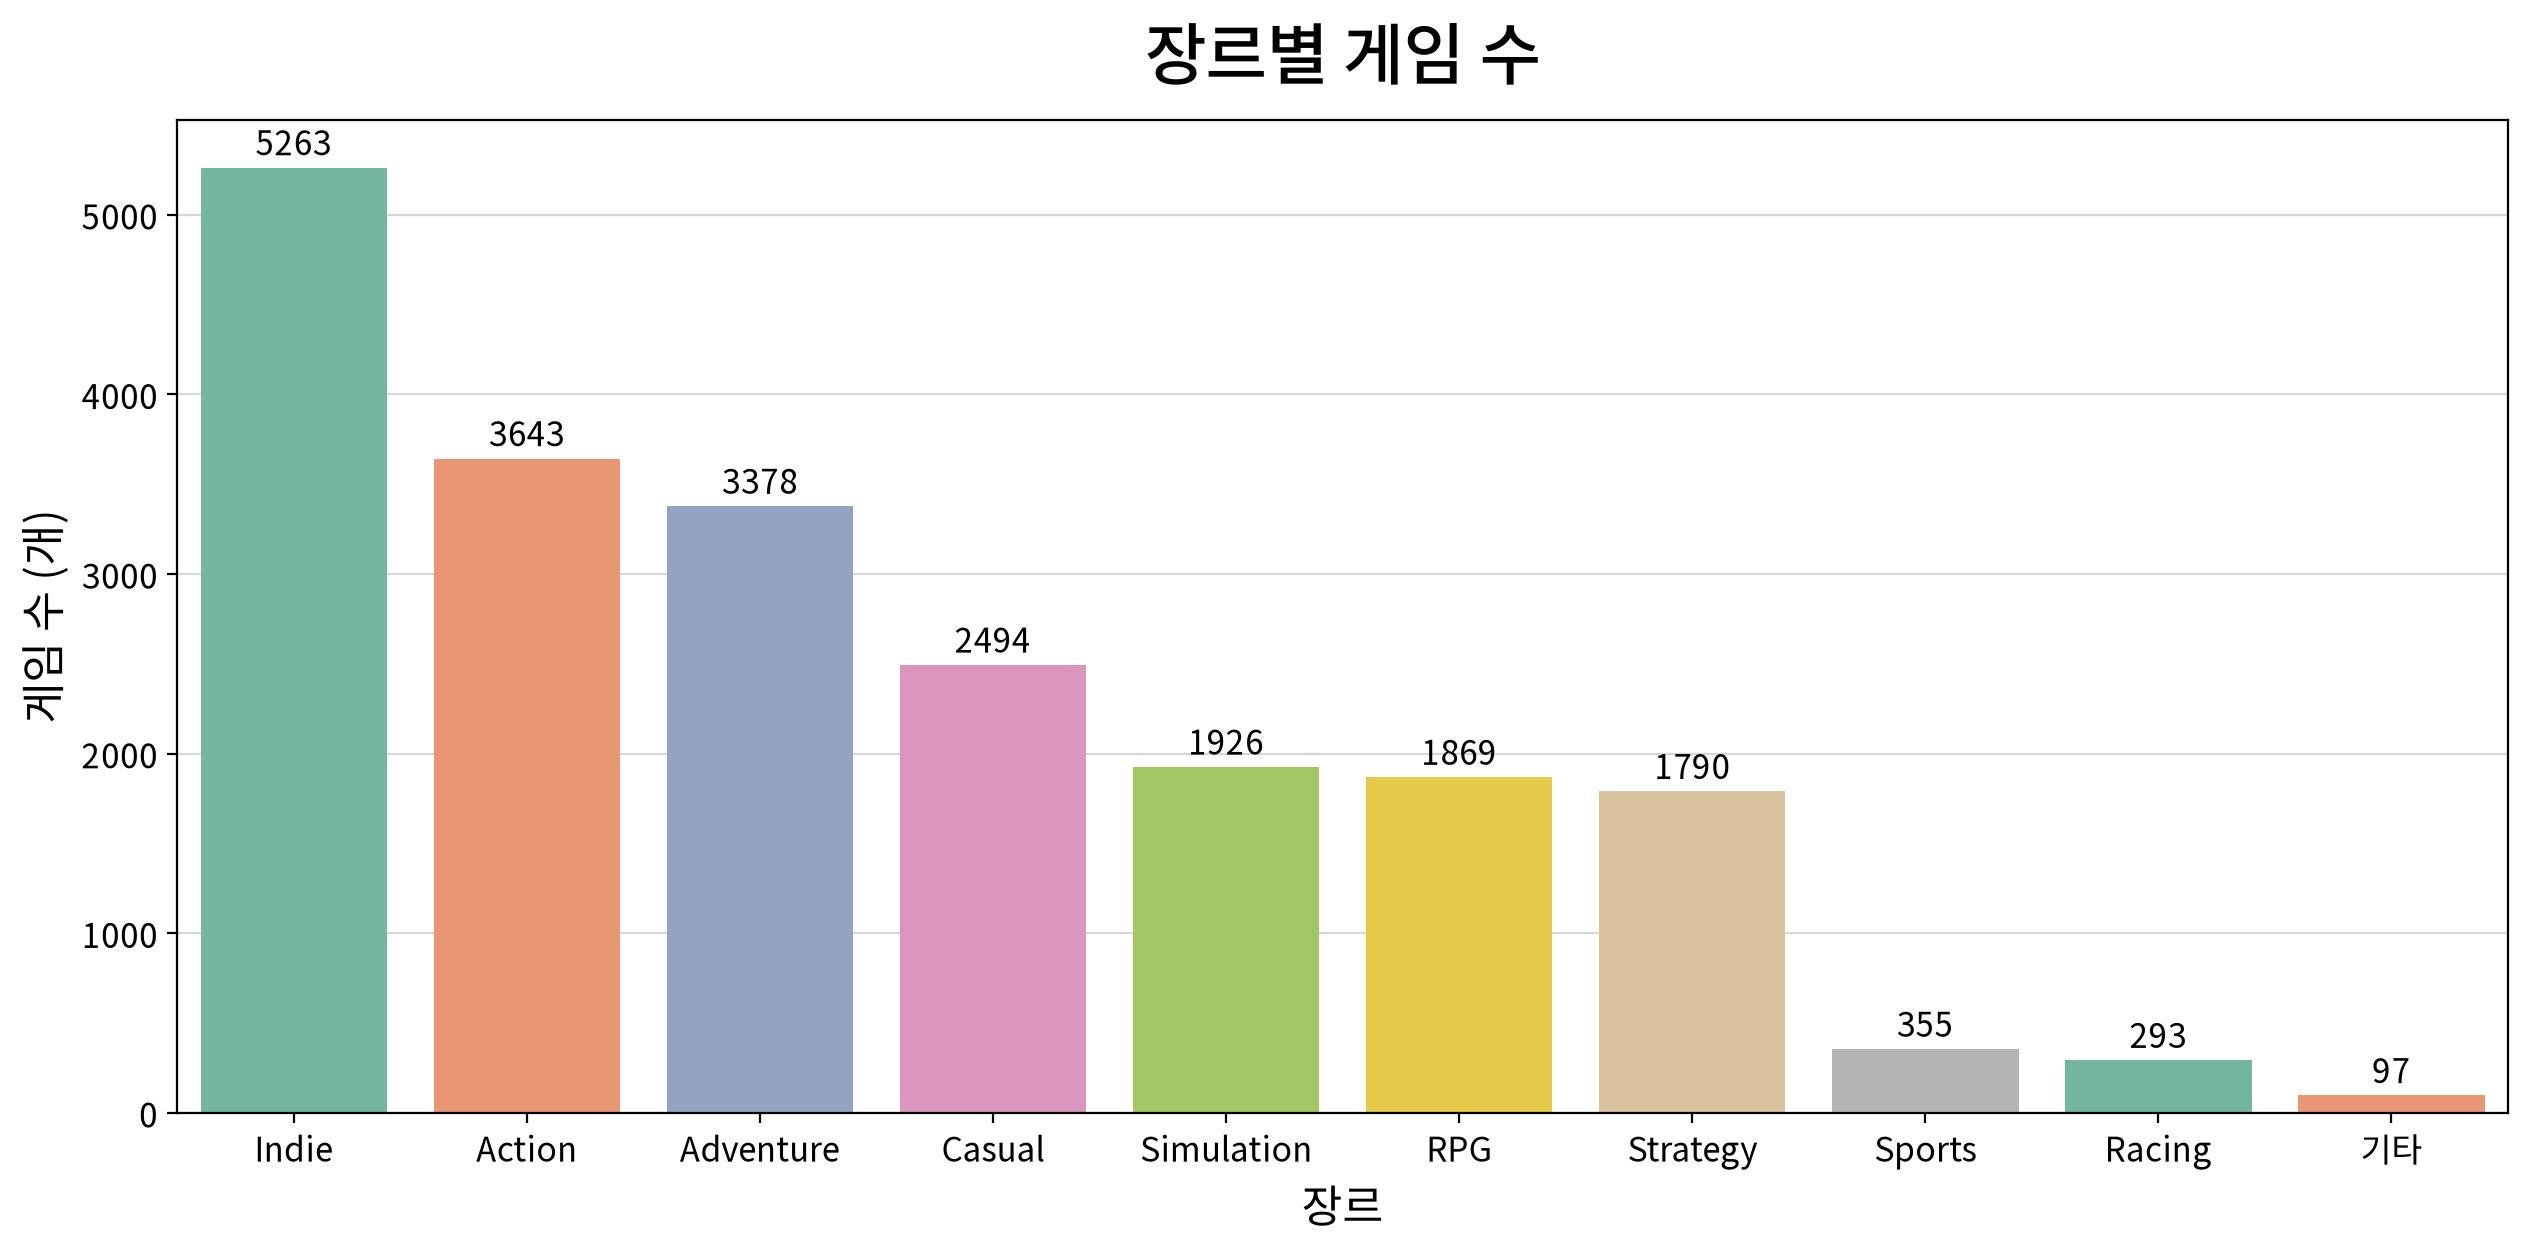

In [50]:
# 장르별 게임 수 막대그래프 그리기
my_plot.barplot(data=genre_summary, x='장르', y='게임 수', palette='Set2',
                title='장르별 게임 수', xlabel='장르', ylabel='게임 수 (개)', text=True)

> 각 막대는 해당 장르에 속한 게임 수를 나타내며, 하나의 게임이 여러 장르에 중복 포함될 수 있다.    
> 선정한 9개 장르 중 어느 장르에도 해당하지 않는 게임은 `기타`로 분류하며, 장르 정보가 비어 있는 게임 20개는 제외한다.   
> 복수 장르 게임이 여러 장르에 중복 집계되므로 장르별 집단이 서로 독립적이지 않다는 한계가 있다.
> -  장르
>    - `Action` 
>    - `Adventure`
>    - `Casual`
>    - `Simulation`
>    - `RPG`
>    - `Strategy`
>    - `Sports`
>    - `Racing`
>    - `Indie`
>    - `기타`

> 추가로, 계획서 예상② (동일한 가격대에서 RPG와 Action 장르 게임의 플레이타임 중앙값이 차이가 없을 것이다.) 를 위해 RPG 와 Action 에 동시에 속한 게임 수를 확인한다.

In [51]:
df2[(df2['RPG'] == 1) & (df2['Action'] == 1)]

,appid,name,price,genres,dlc_count,achievements,median_playtime_forever,average_playtime_forever,가격대,도전과제,...,Indie,Action,Adventure,Casual,Simulation,RPG,Strategy,Sports,Racing,기타
7,252490,Rust,39.99,"['Action', 'Adventure', 'Indie', 'Massively Mu...",4,92,3675,21195,20달러 이상,41개 이상,...,1,1,1,0,0,1,0,0,0,0
12,1245620,ELDEN RING,59.99,"['Action', 'RPG']",2,42,5675,11768,20달러 이상,41개 이상,...,0,1,0,0,0,1,0,0,0,0
26,346110,ARK: Survival Evolved,14.99,"['Action', 'Adventure', 'Indie', 'Massively Mu...",15,32,821,13066,10~20달러 미만,21~40개,...,1,1,1,0,0,1,0,0,0,0
29,218620,PAYDAY 2,9.99,"['Action', 'RPG']",78,1328,560,6933,5~10달러 미만,41개 이상,...,0,1,0,0,0,1,0,0,0,0
39,322330,Don't Starve Together,14.99,"['Action', 'Adventure', 'Indie', 'RPG', 'Simul...",48,0,511,3251,10~20달러 미만,0개,...,1,1,1,0,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72199,652550,Vickinachi,0.99,"['Action', 'Adventure', 'RPG']",0,26,1,1,0달러 초과~5달러 미만,21~40개,...,0,1,1,0,0,1,0,0,0,0
72206,857240,The Prison Experiment: Battle Royale,2.99,"['Violent', 'Action', 'Indie', 'Massively Mult...",0,0,3,3,0달러 초과~5달러 미만,0개,...,1,1,0,0,0,1,1,0,0,0
72594,385890,Golden Rush,0.00,"['Action', 'Free To Play', 'Massively Multipla...",0,61,3,3,무료,41개 이상,...,0,1,0,0,0,1,1,0,0,0
74124,613850,Radiant Crusade,7.99,"['Action', 'Indie', 'Racing', 'RPG', 'Simulati...",0,0,12,12,5~10달러 미만,0개,...,1,1,0,0,1,1,1,0,1,0


> 조회 결과, 비교하려는 두 장르 `RPG`와 `Action`에 동시에 속한 게임은 817개로 확인되었다.

### #04 전처리 및 분석 범위 확정

#### 1. 주요 극단값 점검 결과

| 변수 | 전체 Cleaned 데이터 | 분석 대상 (`median_playtime_forever > 0`) |
|---|---|---|
| ① `price` | 999.98달러 | 99.99달러 |
| ② `dlc_count` | 3,427개 | 2,004개 |
| ③ `achievements` | 9,821개 | 5,000개 |
| ④ `median_playtime_forever` | 1,462,997분 등 상위 5개 게임 | 1,462,997분 등 상위 5개 게임 |

> **판단 근거**
> 
> ① `price`: 플레이타임 중앙값이 양수인 분석 대상에서 이미 제외된 값으로, 분석 대상 유료 게임의 최댓값은 99.99달러이다.   
> ② `dlc_count`: DLC 유무로 범주화하므로 극단값이 범주 분류에 영향을 주지 않는다.   
> ③ `achievements`: 도전과제 개수 구간으로 범주화하므로 극단값이 범주 분류에 영향을 주지 않는다.   
> ④ `median_playtime_forever`: 데이터 오류로 판단할 근거가 없어 극단값을 유지한다. 극단값이 평균에 큰 영향을 줄 수 있으므로 중앙값과 IQR을 중심으로 분석하고 평균은 참고 지표로 활용한다.


#### 2. 분석 기준 및 전처리 계획

| | 구분 | 적용 기준 |
|---|---|---|
| ① | 데이터셋 선정 | 2025년 3월 `cleaned` 데이터 사용 |
| ② | 분석 대상 제한 | `median_playtime_forever > 0` |
| ③ | 가격 구간 | `무료` / `0달러 초과~5달러 미만` / `5~10달러 미만` / `10~20달러 미만` / `20달러 이상` |
| ④ | 도전과제 구간 | `0개` / `1~20개` / `21~40개` / `41개 이상` |
| ⑤ | DLC 구분 | 0개: `없음` / 1개 이상: `있음` |
| ⑥ | 장르 선정 | `Action`, `Adventure`, `Casual`, `Simulation`, `RPG`, `Strategy`, `Sports`, `Racing`, `Indie`, `기타` |
| ⑦ | 복수 장르 처리 | 다중 핫 인코딩 적용 및 장르별 중복 집계 허용 |
| ⑧ | 극단값 처리 및 영향 확인 | 확인된 극단값 유지. 중앙값·IQR 중심으로 보고하고 평균은 참고로 제시. 가격대·장르별 게임 수와 최댓값 함께 표시 |

### #05 변수별 전처리 확인

In [52]:
df3 = df2.copy()

# 데이터 정보 확인
df3.info()

<class 'pandas.DataFrame'>
Index: 8010 entries, 0 to 88392
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   appid                     8010 non-null   int64   
 1   name                      8010 non-null   str     
 2   price                     8010 non-null   float64 
 3   genres                    8010 non-null   str     
 4   dlc_count                 8010 non-null   int64   
 5   achievements              8010 non-null   int64   
 6   median_playtime_forever   8010 non-null   int64   
 7   average_playtime_forever  8010 non-null   int64   
 8   가격대                       8010 non-null   category
 9   도전과제                      8010 non-null   category
 10  DLC                       8010 non-null   category
 11  Indie                     8010 non-null   int64   
 12  Action                    8010 non-null   int64   
 13  Adventure                 8010 non-null   int64   
 14  Casual 

In [53]:
# 분석에 불필요한 변수를 제거
df3.drop(['price', 'genres', 'dlc_count', 'achievements', 'average_playtime_forever'],
         axis=1, inplace=True)

playtime = df3.pop('median_playtime_forever')
df3.insert(loc=len(df3.columns), column='median_playtime', value=playtime)

df3.head()

,appid,name,가격대,도전과제,DLC,Indie,Action,Adventure,Casual,Simulation,RPG,Strategy,Sports,Racing,기타,median_playtime
0,730,Counter-Strike 2,무료,1~20개,있음,0,1,0,0,0,0,0,0,0,0,5174
2,570,Dota 2,무료,0개,있음,0,1,0,0,0,0,1,0,0,0,898
3,271590,Grand Theft Auto V Legacy,무료,41개 이상,없음,0,1,1,0,0,0,0,0,0,0,7101
4,359550,Tom Clancy's Rainbow Six® Siege,0달러 초과~5달러 미만,0개,있음,0,1,0,0,0,0,0,0,0,0,2434
7,252490,Rust,20달러 이상,41개 이상,있음,1,1,1,0,0,1,0,0,0,0,3675


In [54]:
# 전처리가 끝난 데이터를 csv로 내보낸다
df3.to_csv("steam_clean.csv", index=False)

### #06 걱정되는 점과 대응

#### 1. 걱정되는 점

> ① 플레이타임 중앙값 0값 제외에 따른 표본 편향   
> ② 장르별 중복 집계로 인한 독립성 문제   
> ③ 플레이타임 중앙값의 극단값에 따른 분석 결과 왜곡 가능성  
> ④ 출시 경과 기간에 따른 플레이타임 중앙값의 증가 가능성

#### 2. 대응

> **① 표본 편향:**
> - 플레이타임 중앙값이 0인 게임(81,608개, 91.06%)과 양수인 게임(8,010개, 8.94%)의 기술통계량을 비교한 결과, 가격·DLC 수·도전과제 수에서 차이가 확인되었다.
> - 장르 중 Casual 게임도 0인 게임(약 17%)과 양수인 게임(12%)의 차이가 확인되었다.
> - 따라서 플레이타임 중앙값 양수 집단만 분석할 경우 특정 특성을 가진 게임이 상대적으로 많이 반영될 가능성이 있으므로, 선택 편향 가능성을 한계로 명시하고 분석 결과의 해석 범위를 플레이타임 중앙값이 양수인 게임으로 제한한다.
> - 따라서 본 분석의 분석 대상(게임 8,010개)은 플레이 기록이 잡힐 만큼 소유자가 많은 게임이다.
>   - 3주차 결론에서 주어는 `Steam 게임`이 아니라 `Steam 인기 게임`으로 작성한다.
>
> **② 장르 중복:**
> - 원본 데이터의 장르가 대부분 알파벳순으로 정렬되어 있어 대표 장르를 판단하기 어려우므로 중복 집계를 허용한다.
> - `Free To Play`, `Early Access`, `Massively Multiplayer`를 제외한 게임 수 기준 상위 9개 장르를 개별적으로 집계하고, 해당 장르에 하나도 속하지 않는 게임은 `기타`로 분류한다.
> - 복수 장르 게임은 여러 주요 장르에 중복 포함될 수 있으므로 장르별 집단 간 독립성이 확보되지 않는다는 한계를 명시한다.
> - 비교하려는 두 장르 `RPG`와 `Action`에 동시에 속한 게임은 817개로 확인된다.
> - 2주차 `그래프 ②`(가격대 × 장르 히트맵)의 칸마다 게임 수를 함께 표시한다.
>
> **③ 극단값:**
> - 플레이타임 중앙값의 사분위수와 IQR을 이용하여 극단값 후보를 확인한다.
> - 확인된 극단값은 오류로 판단할 근거가 없어 유지하되, 극단값이 평균에 미치는 영향을 고려하여 중앙값과 IQR을 중심으로 분석하고 평균은 참고 지표로 활용한다.
> - 또한 가격대·장르별 게임 수와 최댓값을 함께 표시하여 극단값의 영향을 확인한다.
> - 플레이타임 중앙값의 분포 및 가격대별 차이에 대한 시각적 가독성을 확보하기 위해 2주차 `그래프 ①` (Boxplot)의 세로축을 로그 눈금으로 그리고 잘려서 안 보이는 게임 수를 캡션에 적는다.
> 
> **④ 출시일:**
> - 출시 연도별 플레이타임 중앙값을 비교한 결과, 출시 경과 기간과 플레이타임 사이에 뚜렷하고 일관된 관계가 관찰되지 않았다.
> - 따라서 본 분석에서는 출시 경과 기간을 주요 분석 변수에서 제외한다.
> - 다만 영향이 전혀 없음을 의미하지는 않으므로 분석의 한계로 명시한다.